In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection

from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

# GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
import optuna

from sklearn.preprocessing import StandardScaler  # уточнить
from sklearn.base import BaseEstimator, TransformerMixin

# Metrics
from sklearn.metrics import accuracy_score

# Pipeline
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestClassifier

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import graphviz

import joblib

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

In [2]:
SEED = 42

In [3]:
# Download train data
data = pd.read_csv("train_data.csv")

In [4]:
X_cols = [
    "FamilyID",
    "Pclass",
    "Sex",
    "Embarked",
    "Initial",
    "Age_band",
    "Rich_Woman",
    "Alone",
    "Family_size",
    "Fare_cat",
    "Age*Class",
]
all_cols = X_cols + ["Survived"]

In [5]:
assert set(data.columns.to_list()) == set(all_cols)
assert len(data.columns.to_list()) == len(all_cols)

### Функции утилиты

In [6]:
# Отбирает из результатов все значения с целевым, а остальные по указаному фиксу
def draw_parameter(results, parameter, fixed_params):

    my_params = fixed_params.copy()
    param_to_check = parameter
    del my_params[param_to_check]

    data = results.copy()

    for key, value in my_params.items():
        column = f"param_{key}"

        data = data[data[column] == value]

    plt.figure(figsize=(16, 8))
    plt.errorbar(
        x=data[f"param_{parameter}"].astype(float),
        y=data["mean_test_score"],
        yerr=data["std_test_score"],
        marker="o",
    )

    plt.xlabel(parameter)
    plt.ylabel("CV accuracy")
    plt.title(f"Accuracy vs {parameter}")
    plt.show()

In [7]:
def draw_heatmap(results, parameter_x, parameter_y, fixed_params):

    my_params = fixed_params.copy()

    # Эти два параметра должны изменяться
    del my_params[parameter_x]
    del my_params[parameter_y]

    data = results.copy()

    # Фиксируем остальные параметры
    for key, value in my_params.items():
        column = f"param_{key}"

        data = data[data[column] == value]

    # Приводим параметры к числам
    data[parameter_x] = data[f"param_{parameter_x}"].astype(float)
    data[parameter_y] = data[f"param_{parameter_y}"].astype(float)

    # Создаем таблицу для heatmap
    heatmap_data = data.pivot(
        index=parameter_y, columns=parameter_x, values="mean_test_score"
    )

    plt.figure(figsize=(14, 8))

    sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap="viridis")

    plt.xlabel(parameter_x)
    plt.ylabel(parameter_y)
    plt.title(f"CV accuracy: {parameter_y} vs {parameter_x}")

    plt.show()

In [8]:
# Рисуем графики ШАП для интерпретации моделей
def draw_shap_plots(shap_values, sample_idx, feature_names=None):
    if feature_names is not None:
        shap_values.feature_names = feature_names

    shap.plots.beeswarm(shap_values)

    shap.plots.waterfall(shap_values[sample_idx])

    shap.plots.bar(shap_values)

### Предобработка

In [10]:
data.isnull().sum()

Survived       0
Pclass         0
Sex            0
Embarked       0
Initial        0
Age_band       0
Rich_Woman     0
Alone          0
Family_size    0
FamilyID       0
Fare_cat       0
Age*Class      0
dtype: int64

In [9]:
X_train = data[X_cols]
y_train = data["Survived"]

### Валидация

In [11]:
class FeatureTranformer(BaseEstimator, TransformerMixin):
    def __init__(self, m: int = 5, y_: float = 0.38):
        self.X_cols = X_cols
        self.m = m
        self.y_ = y_

    def fit(self, X, y):
        # обучаемся только на train fold
        # сохраняем stat
        self.y_ = y.mean()
        X = pd.concat([X, y], axis=1)
        X["Family_TE"] = (
            X["FamilyID"].map(X.groupby("FamilyID")["Survived"].sum())
            + self.m * self.y_
        ) / (X["Family_size"] + 1 + self.m)
        self.stat = X[["FamilyID", "Family_TE"]].drop_duplicates(subset=["FamilyID"])
        self.stat = self.stat.set_index("FamilyID")["Family_TE"]
        return self

    def transform(self, X):
        # используем сохранённые stat
        X_transformed = X.copy()
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(self.stat).fillna(self.y_)
        )
        X_transformed = X_transformed.drop(columns=["FamilyID"])

        return X_transformed

    def fit_transform(self, X, y=None):
        # специальная логика получения train-feature без leakage

        self.fit(X, y)
        X_transformed = pd.concat([X, y], axis=1)
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(
                X_transformed.groupby("FamilyID")["Survived"].sum()
            )
            - X_transformed["Survived"]
            + self.m * self.y_
        ) / (X_transformed["Family_size"] + self.m)

        X_transformed = X_transformed.drop(columns=["FamilyID", "Survived"])

        return X_transformed

In [12]:
def search_params(
    X, y, cv_obj, pipline, parameters, key_param, type_of_search=GridSearchCV
):

    CV_model = type_of_search(
        pipline,
        parameters,
        cv=cv_obj,
        scoring="accuracy",
        n_jobs=-1,
        verbose=0,
        refit=True,
    )

    n_candidates = len(list(sklearn.model_selection.ParameterGrid(parameters)))
    total_fits = n_candidates * cv_obj.get_n_splits()

    with tqdm_joblib(tqdm(total=total_fits, desc="GridSearchCV")):
        CV_model.fit(X, y)

    results = pd.DataFrame(CV_model.cv_results_)

    draw_parameter(results, parameter=key_param, fixed_params=CV_model.best_params_)
    return (
        CV_model.best_estimator_,
        CV_model.best_params_,
        CV_model.best_score_,
        results,
    )

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### Logistic Regression

In [237]:
# models = [LogisticRegression]
param_names = {
    "feature__m": [0, 1, 2, 4, 5],
    "model__C": np.linspace(
        0.001, 20, 20
    ),  # [np.float64(1.053578947368421)], #np.linspace(0.001,20,20),
    "model__penalty": ["l2", "l1", "elasticnet"],  # ['l2','l1','elasticnet'],
    "model__solver": ["saga"],
    "model__max_iter": [1000],
    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],  # [0.1, 0.3, 0.5, 0.7, 0.9],
    "model__random_state": [SEED],
    "model__n_jobs": [-1],
}

In [238]:
pipe = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression()),
    ]
)

GridSearchCV:   0%|          | 0/7500 [00:00<?, ?it/s]

  0%|          | 0/7500 [00:00<?, ?it/s]

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
1500 fits failed out of a total of 7500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1200 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\user\AppData\Roaming\Python\Python313\site

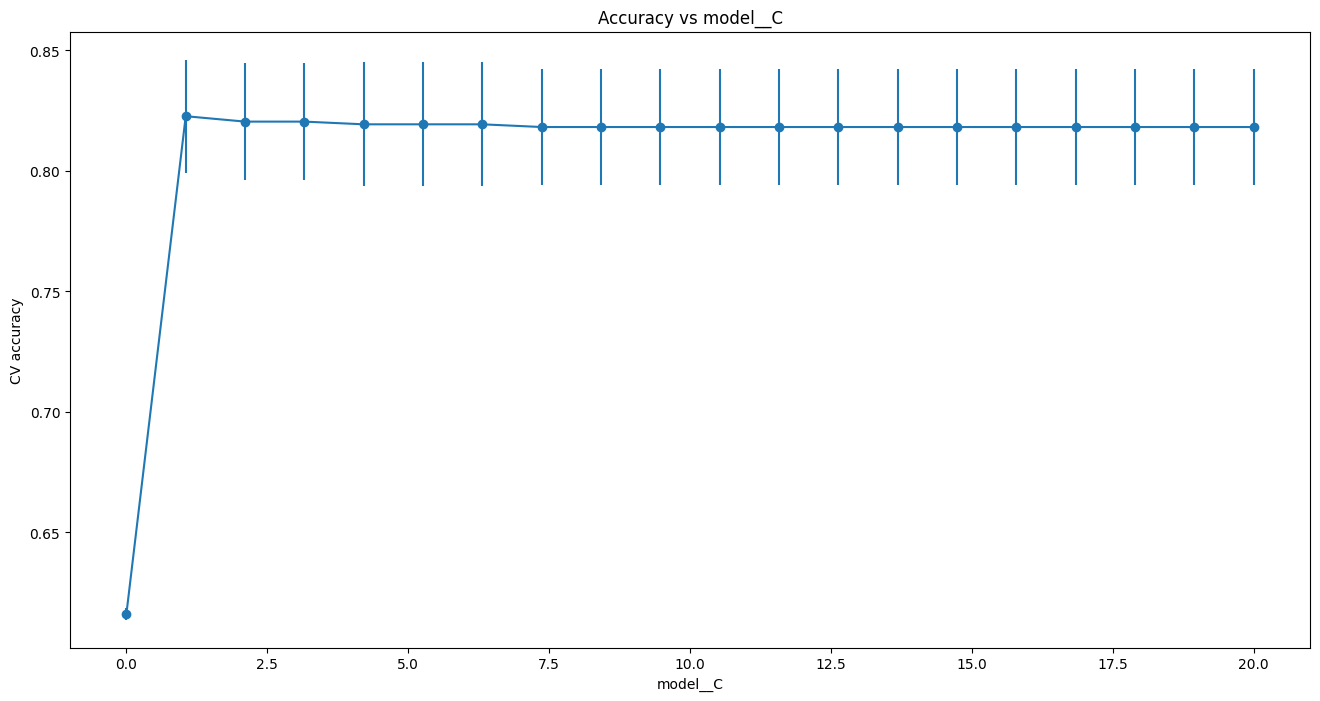

{'feature__m': 4, 'model__C': np.float64(1.053578947368421), 'model__l1_ratio': 0.1, 'model__max_iter': 1000, 'model__n_jobs': -1, 'model__penalty': 'l1', 'model__random_state': 42, 'model__solver': 'saga'} 0.822666499278137


In [239]:
best_logregression, best_param, best_scor, result = search_params(
    X_train, y_train, skf, pipe, param_names, key_param="model__C"
)
print(best_param, best_scor)

In [312]:
joblib.dump(
    best_logregression,
    f".\\Models\\logreg_best{str(best_scor).replace('.', 'dot')}.pkl",
)

PicklingError: Can't pickle <class '__main__.FeatureTranformer'>: it's not the same object as __main__.FeatureTranformer

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


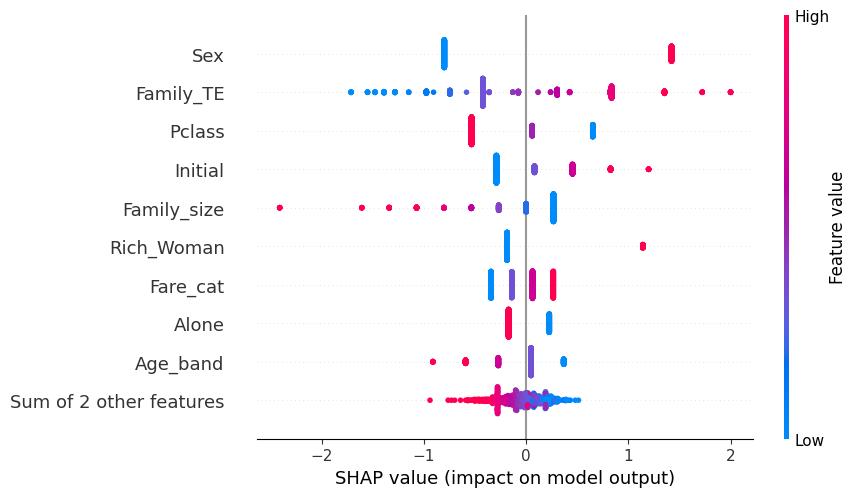

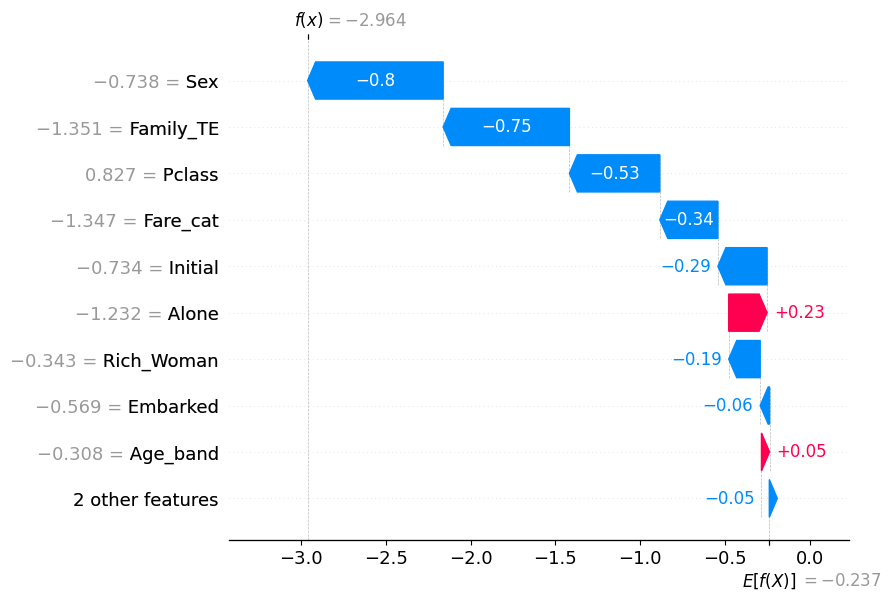

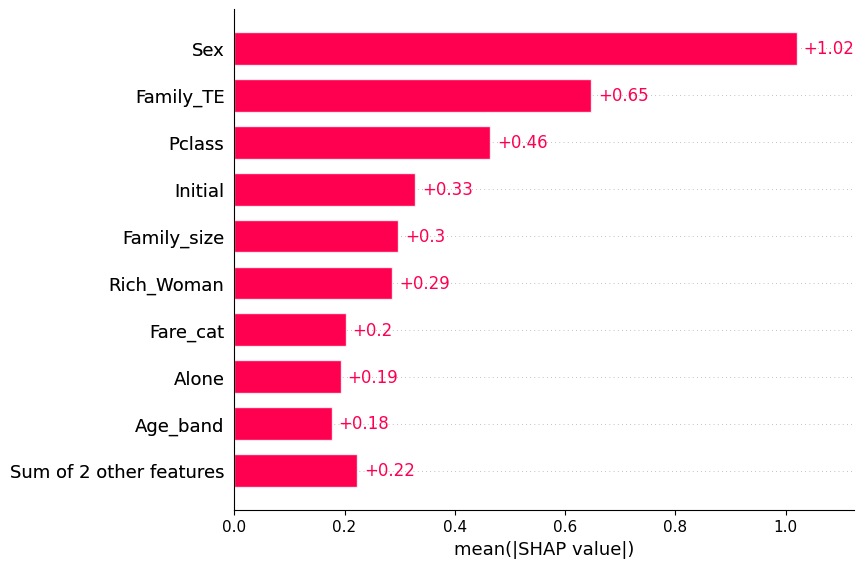

In [240]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_logregression.named_steps["feature"].transform(X_train)

# 2. Получаем модель
logregression_model = best_logregression.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_logregression[:-1].transform(X_train)

# 4. SHAP
explainer = shap.LinearExplainer(logregression_model, X_train_transformed)

shap_values_log_reg = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_log_reg, sample_idx=0, feature_names=feature_names)

### KNN

In [270]:
param_names_knn = {
    "feature__m": [1, 2],
    "model__n_neighbors": np.array(np.linspace(4, 30, 15), dtype="int"),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
    "model__n_jobs": [-1],
}

In [271]:
pipe_knn = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier()),
    ]
)

GridSearchCV:   0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/600 [00:00<?, ?it/s]

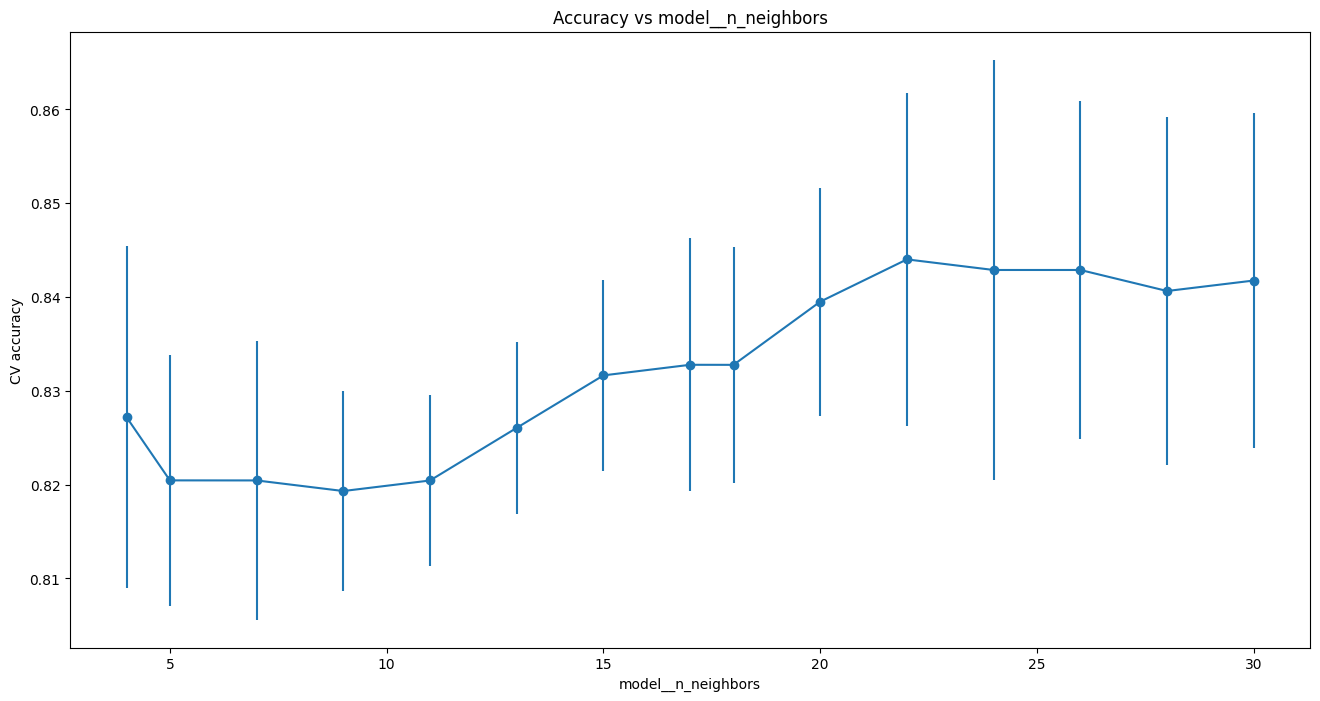

{'feature__m': 2, 'model__n_jobs': -1, 'model__n_neighbors': np.int64(22), 'model__p': 1, 'model__weights': 'uniform'} 0.8440085368150149


In [272]:
best_knn, best_param, best_scor, result = search_params(
    X_train, y_train, skf, pipe_knn, param_names_knn, key_param="model__n_neighbors"
)
print(best_param, best_scor)

Разобраться почему у кнн больший скор

In [313]:
joblib.dump(best_knn, f".\\Models\\knn_best{str(best_scor).replace('.', 'dot')}.pkl")

['.\\Models\\knn_best0dot8552444918711946.pkl']

In [244]:
# # 1. Получаем данные после FeatureTransformer, но до scaler
# X_train_features = best_knn.named_steps['feature'].transform(X_train)

# # 2. Получаем модель
# knn_model = best_knn.named_steps['model']

# # 3. Получаем данные в том виде, в котором их видит LogisticRegression
# X_train_transformed = best_knn[:-1].transform(X_train)

# # 4. SHAP
# explainer = shap.Explainer(lambda x:knn_model.predict_proba(x)[:, 1], X_train_transformed)

# shap_values_knn = explainer(X_train_transformed)

# # 5. Названия признаков
# feature_names = X_train_features.columns.tolist()

# # 6. Графики
# draw_shap_plots(
#     shap_values_knn,
#     sample_idx=0,
#     feature_names=feature_names
# )

Прокоментировать

Давайте сравним важность фичей для этих двух моделей

###  Решающее дерево

In [245]:
param_names = {
    "feature__m": [1, 2],
    "model__max_depth": [3, 4, 5, 6, 7, 8],
    "model__criterion": ["gini"],
    "model__splitter": ["best"],
    "model__min_samples_split": [10, 20, 30, 40, 50],
    "model__min_samples_leaf": [5, 8, 12, 16, 20],
    "model__max_leaf_nodes": [5, 7, 9, 11, 13, 15],  # Лушчее пока 9
    "model__min_impurity_decrease": [0],
    "model__random_state": [SEED],
}

In [246]:
pipe_tree = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier()),
    ]
)

GridSearchCV:   0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

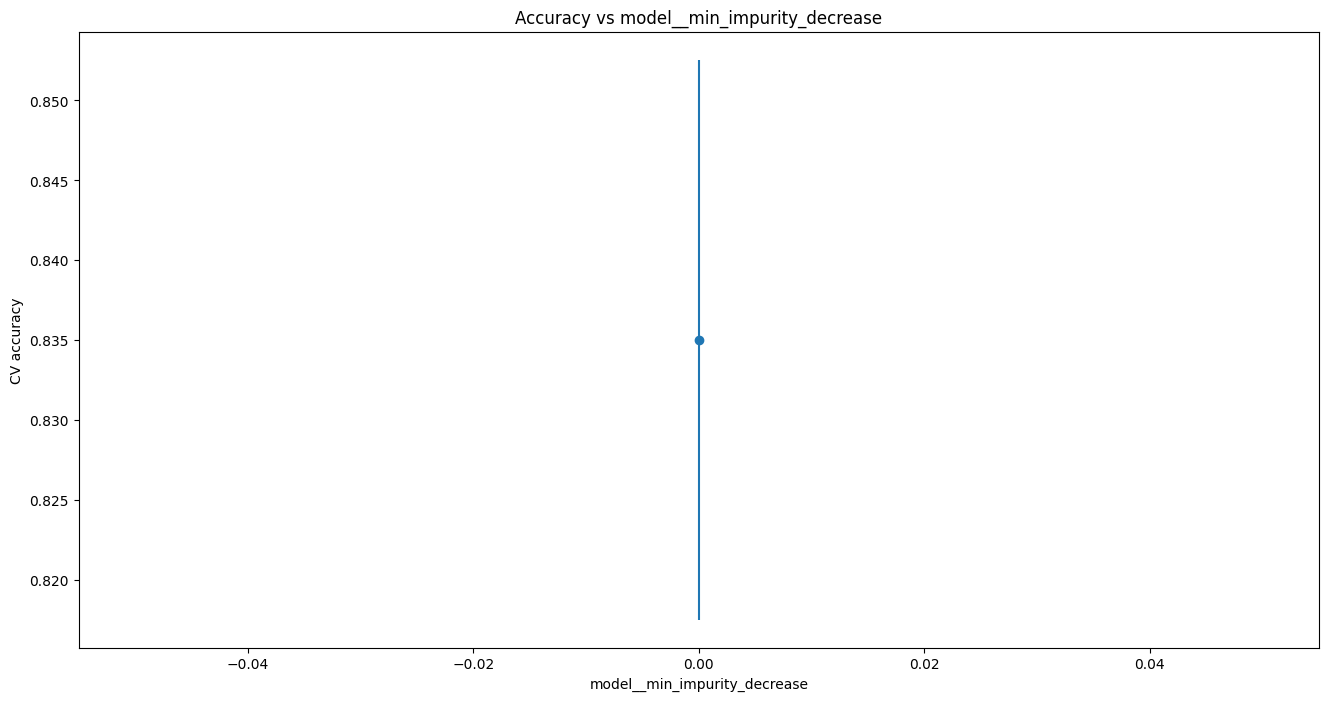

{'feature__m': 1, 'model__criterion': 'gini', 'model__max_depth': 4, 'model__max_leaf_nodes': 7, 'model__min_impurity_decrease': 0, 'model__min_samples_leaf': 20, 'model__min_samples_split': 10, 'model__random_state': 42, 'model__splitter': 'best'} 0.8350260498399347


In [247]:
best_tree, best_param, best_scor, result = search_params(
    X_train,
    y_train,
    skf,
    pipe_tree,
    param_names,
    key_param="model__min_impurity_decrease",
)
print(best_param, best_scor)

In [314]:
joblib.dump(best_tree, f".\\Models\\tree_best{str(best_scor).replace('.', 'dot')}.pkl")

PicklingError: Can't pickle <class '__main__.FeatureTranformer'>: it's not the same object as __main__.FeatureTranformer

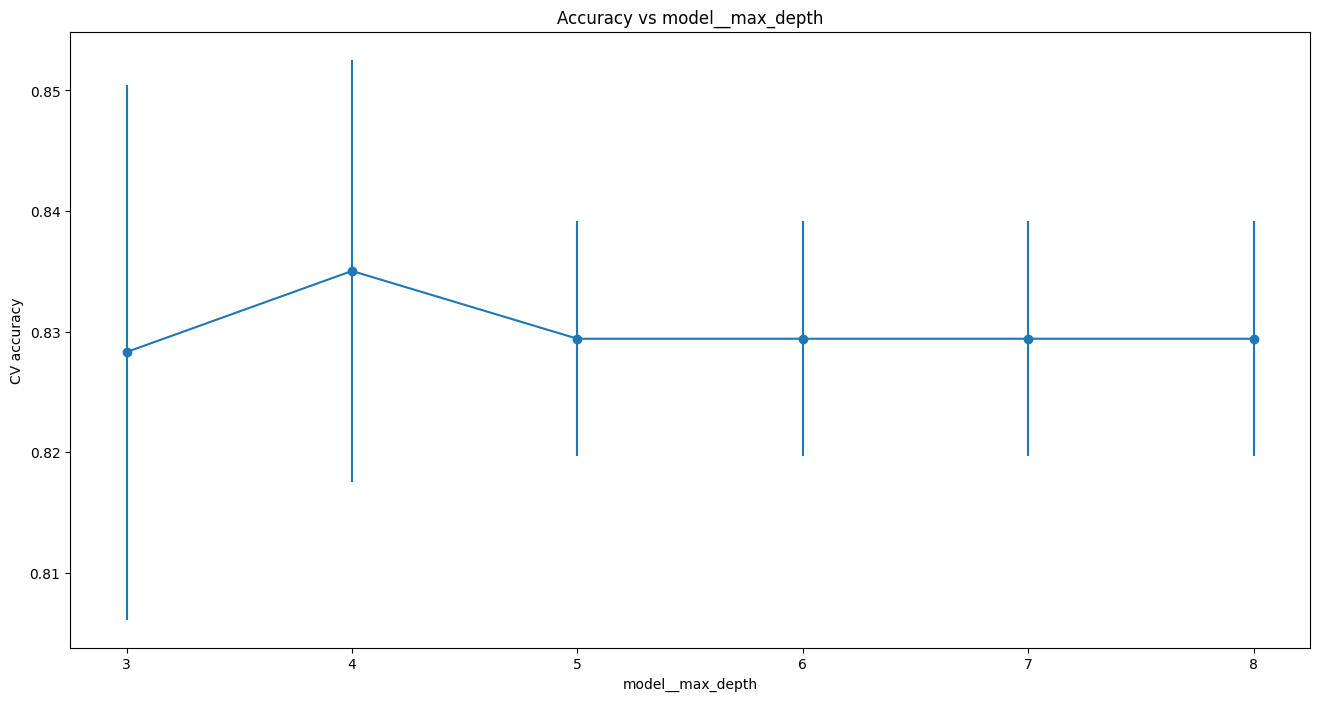

In [248]:
draw_parameter(result, parameter="model__max_depth", fixed_params=best_param)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


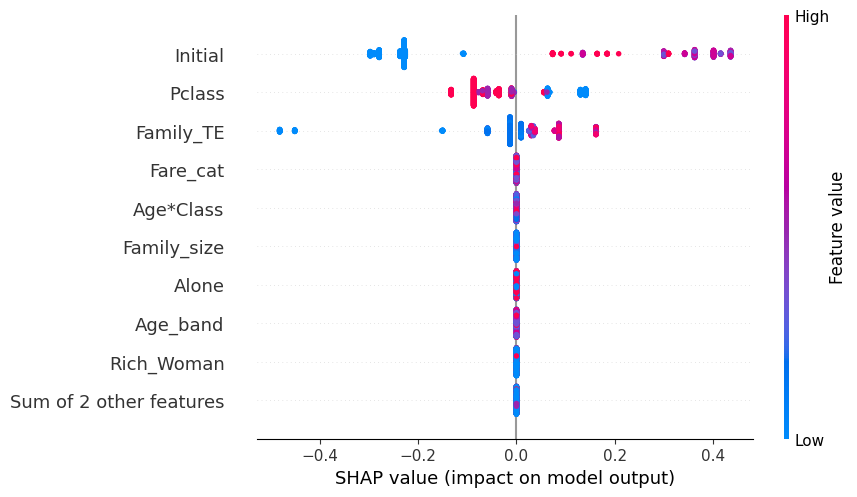

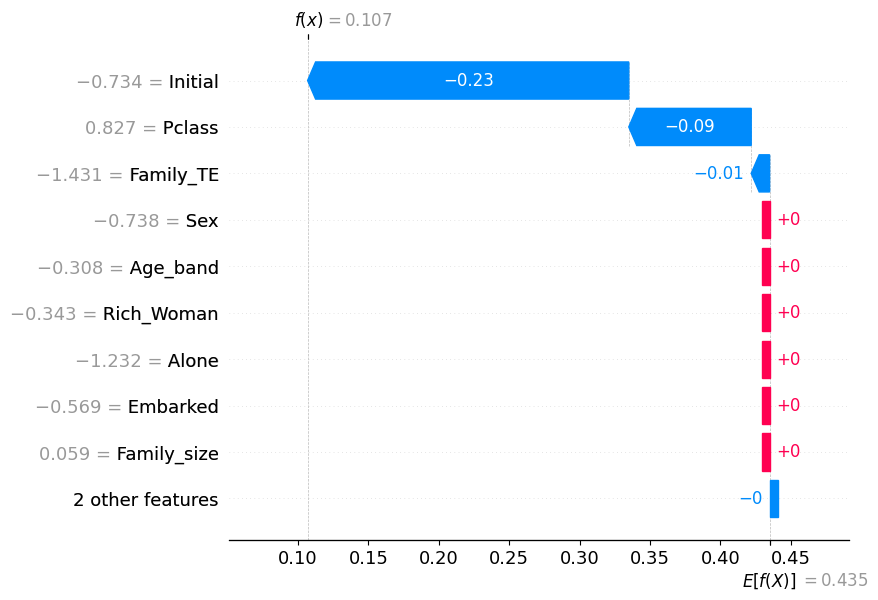

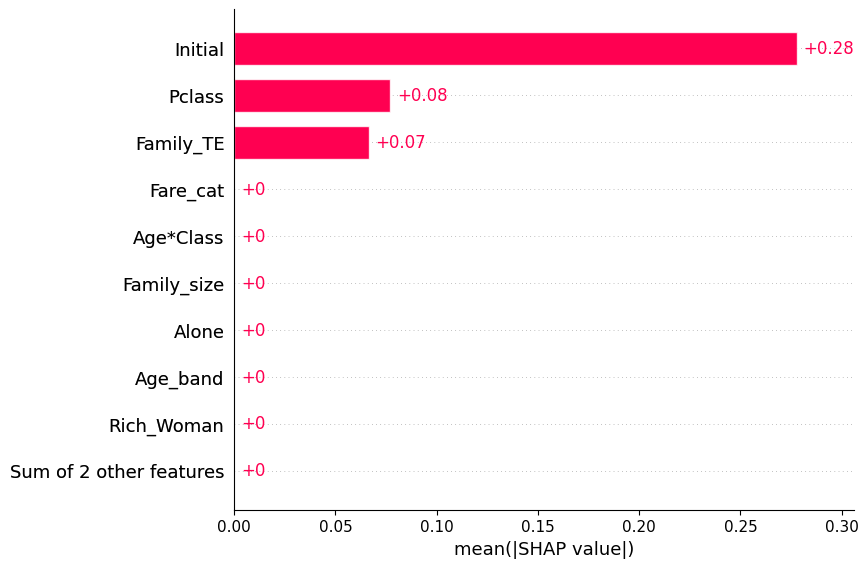

In [249]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_tree.named_steps["feature"].transform(X_train)

# 2. Получаем модель
tree_model = best_tree.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_tree[:-1].transform(X_train)

# 4. SHAP
explainer = shap.TreeExplainer(tree_model, X_train_transformed)

shap_values_tree = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_tree[:, :, 1], sample_idx=0, feature_names=feature_names)

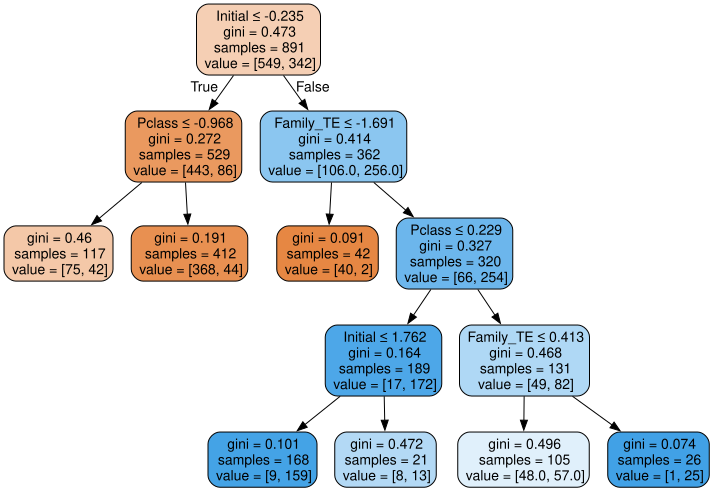

In [250]:
dot_data = export_graphviz(
    tree_model,
    out_file=None,
    filled=True,
    rounded=True,
    special_characters=True,
    feature_names=feature_names,
)
graph = graphviz.Source(dot_data)
graph

Анализ для вкладов фичей в вероятность первого класса

### Random Forest

In [275]:
param_names = [  # bootstrap=True
    {
        "feature__m": [1, 2],
        "model__n_estimators": [50],  # np.linspace(1, 100, 5, dtype=int),
        "model__max_depth": [4, 5, 6],  # np.linspace(1, 10, 5, dtype=int),
        "model__criterion": ["gini"],
        "model__n_jobs": [-1],
        "model__min_samples_split": [15],  # np.linspace(10, 100, 5, dtype=int),
        "model__min_samples_leaf": [
            15
        ],  # np.linspace(5, 15, 5, dtype=int), #'min_samples_leaf': np.int64(6)
        "model__max_leaf_nodes": [11, 12],  # [5,7,9,11],
        "model__min_impurity_decrease": [0],  # [0],
        "model__max_features": ["sqrt", "log2", None],
        "model__bootstrap": [True],
        "model__max_samples": [0.6, 0.8, 1],
        "model__oob_score": [True, False],
        "model__random_state": [SEED],
    }
]

In [276]:
pipe_forest = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier()),
    ]
)

GridSearchCV:   0%|          | 0/1080 [00:00<?, ?it/s]

  0%|          | 0/1080 [00:00<?, ?it/s]

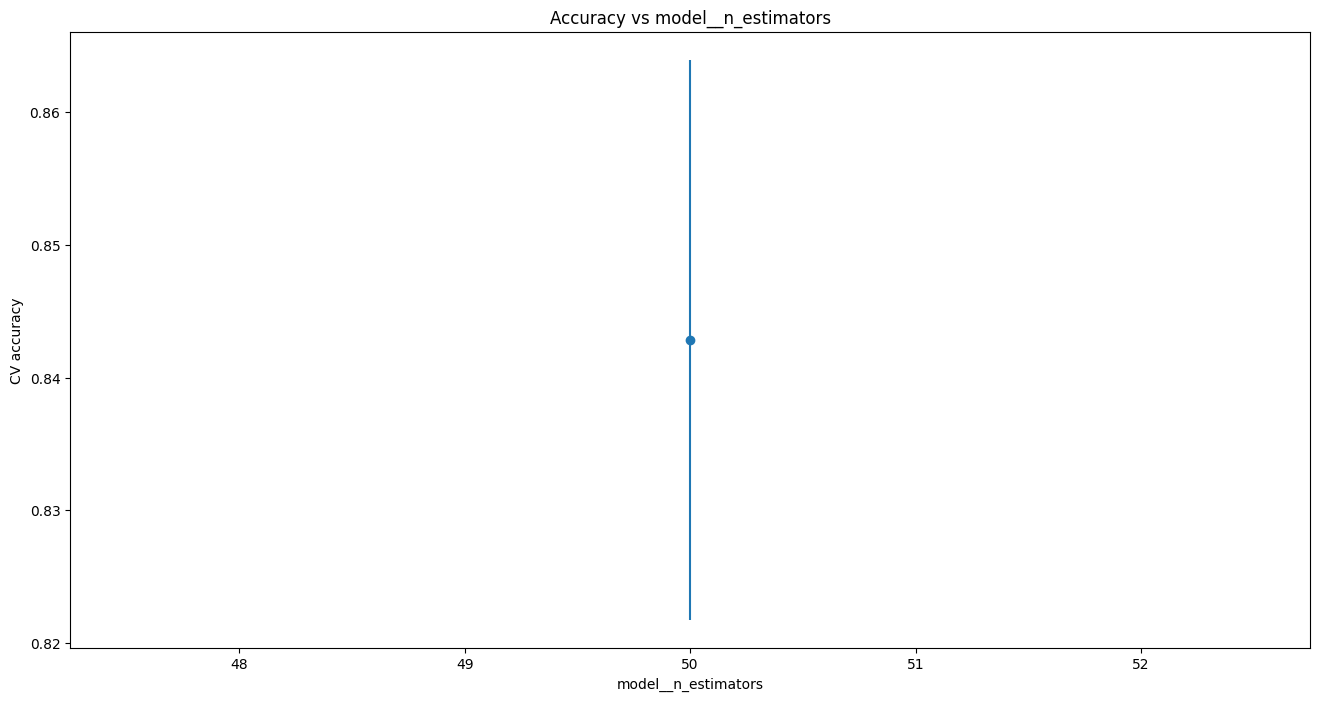

{'feature__m': 1, 'model__bootstrap': True, 'model__criterion': 'gini', 'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__max_leaf_nodes': 11, 'model__max_samples': 0.6, 'model__min_impurity_decrease': 0, 'model__min_samples_leaf': 15, 'model__min_samples_split': 15, 'model__n_estimators': 50, 'model__n_jobs': -1, 'model__oob_score': True, 'model__random_state': 42} 0.8428598330299417


In [277]:
best_forest, best_param, best_scor, result = search_params(
    X_train, y_train, skf, pipe_forest, param_names, key_param="model__n_estimators"
)
print(best_param, best_scor)

In [268]:
joblib.dump(
    best_forest, f".\\Models\\randomforest_best{str(best_scor).replace('.', 'dot')}.pkl"
)

['.\\Models\\randomforest_best0dot8428598330299417.pkl']

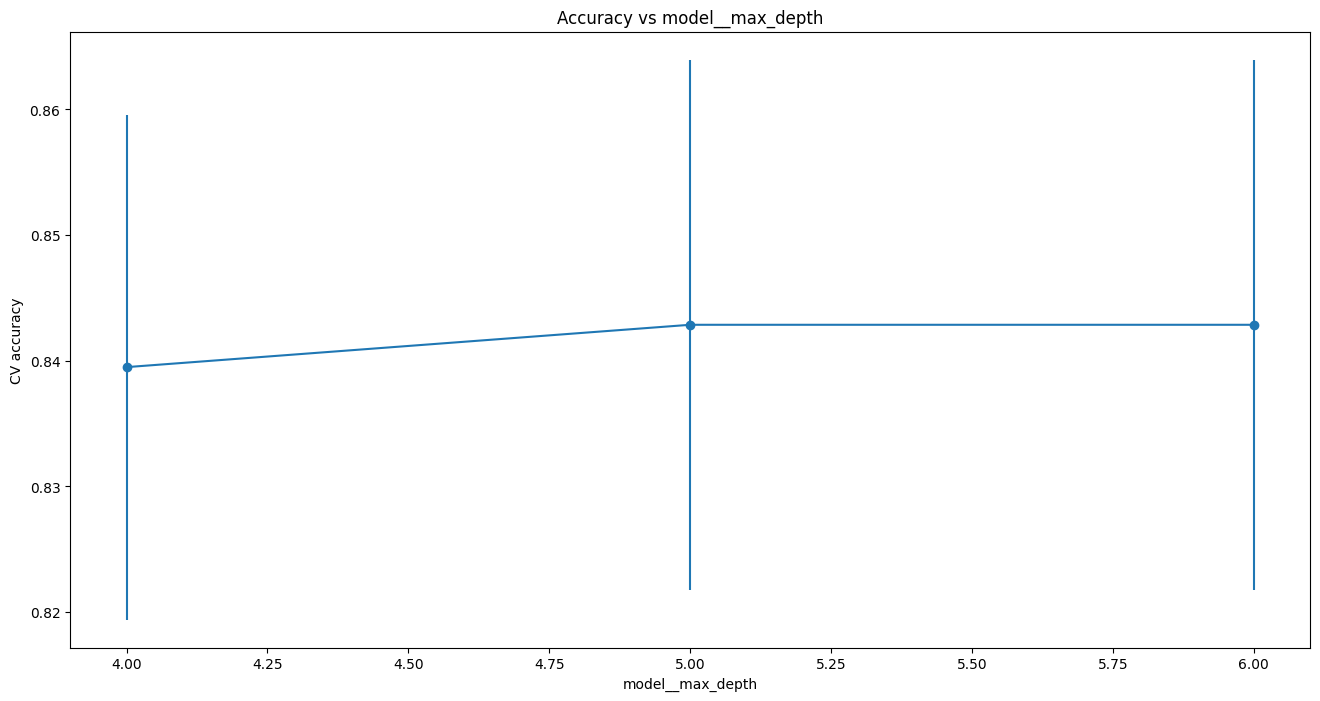

In [278]:
draw_parameter(result, parameter="model__max_depth", fixed_params=best_param)

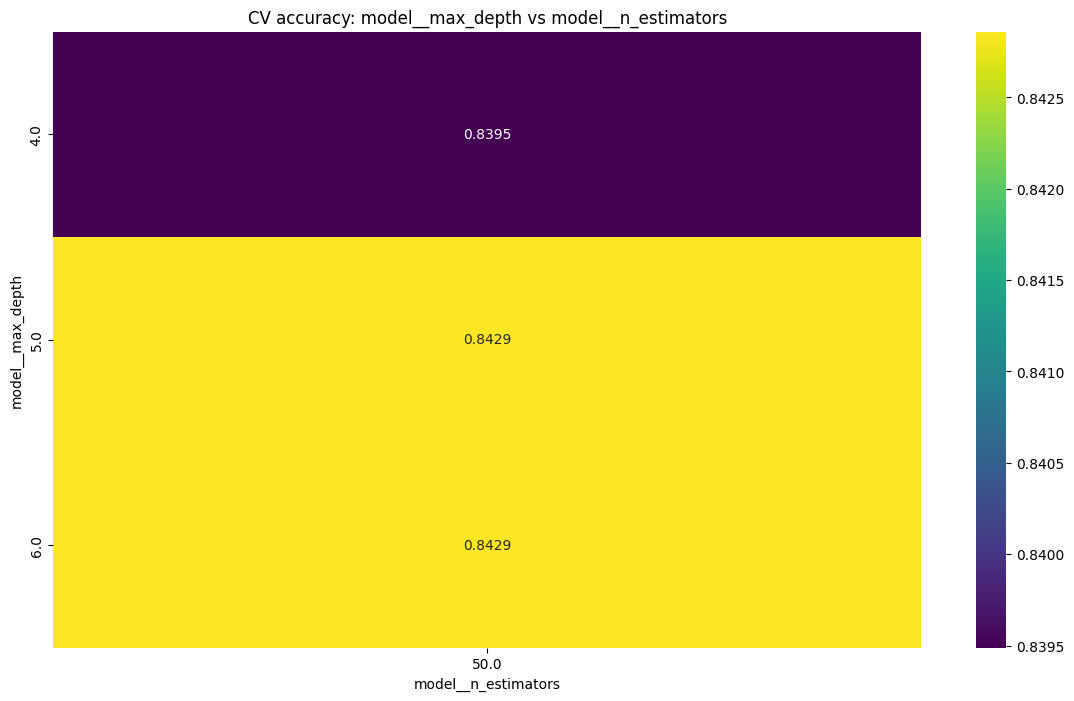

In [279]:
draw_heatmap(
    result,
    parameter_x="model__n_estimators",
    parameter_y="model__max_depth",
    fixed_params=best_param,
)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


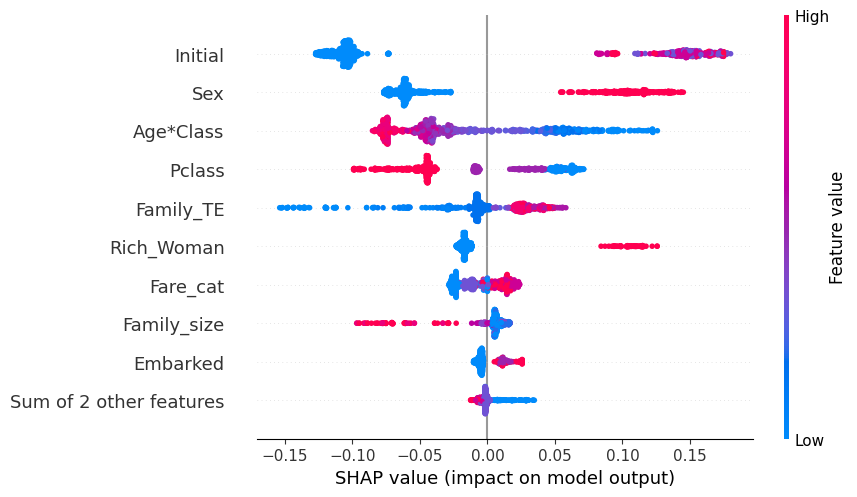

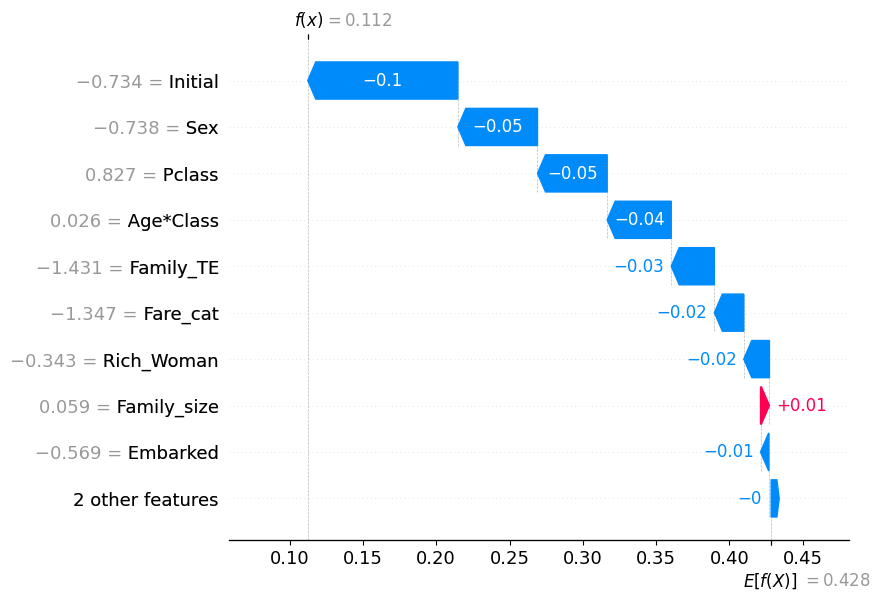

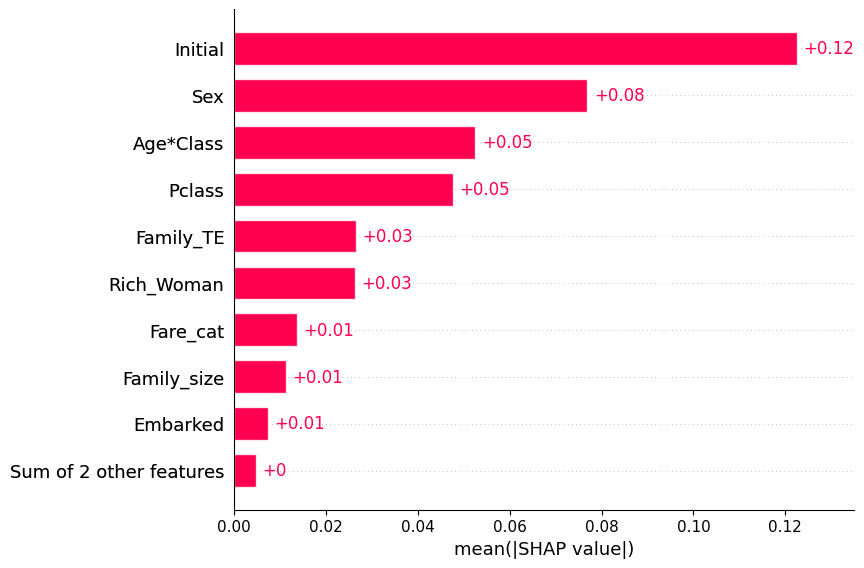

In [280]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_forest.named_steps["feature"].transform(X_train)

# 2. Получаем модель
forest_model = best_forest.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_tree[:-1].transform(X_train)

# 4. SHAP
explainer = shap.TreeExplainer(forest_model, X_train_transformed)

shap_values_forest = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_forest[:, :, 1], sample_idx=0, feature_names=feature_names)

### Бустинги

In [ ]:
param_names = [  # bootstrap=True
    {
        "feature__m": [1, 2],
        "model__device": ["cpu"],
        "model__booster": ["gbtree"],
        "model__tree_method": ["hist"],
        "model__n_estimators": [
            70,
            75,
            80,
        ],  # np.linspace(1, 100, 5, dtype=int),#лучшее 12
        "model__learning_rate": [
            np.float64(0.05500000000000001)
        ],  # np.linspace(0.01,0.1,5, dtype=float),
        "model__max_depth": [
            4,
            5,
            6,
        ],  # [6, 8, 10, 12, 14], #Лучшее 10 для случайного леса
        "model__min_child_weight": [5],  # np.linspace(1,10,5,dtype=int),
        "model__n_jobs": [-1],
        "model__subsample": [0.6],  # [0.6, 0.8, 1.0],
        "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0],
        "model__reg_alpha": [0, 0.01, 0.1, 1],  # [0, 0.01, 0.1, 1],
        "model__reg_lambda": [0.1, 0.5, 5, 10],  # [0.01,0.1,0.5,5,10],
        "model__objective": ["binary:logistic"],
        "model__eval_metric": ["error"],
        "model__gamma": [0, 0.01, 0.1],  # np.linspace(0.01,0.1,10,dtype=float),
        "model__random_state": [SEED],
    }
]

In [288]:
pipe_XGBoost = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", XGBClassifier()),
    ]
)

GridSearchCV:   0%|          | 0/4320 [00:00<?, ?it/s]

  0%|          | 0/4320 [00:00<?, ?it/s]

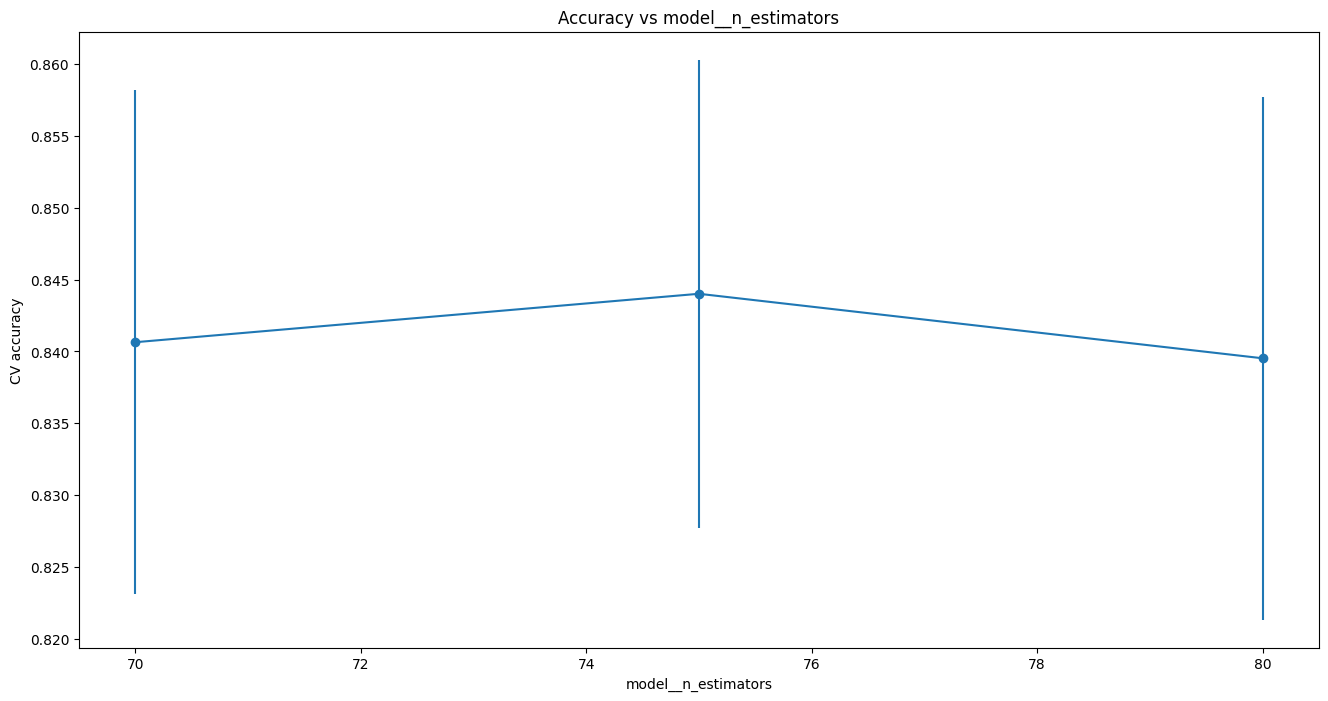

{'feature__m': 2, 'model__booster': 'gbtree', 'model__colsample_bytree': 0.8, 'model__device': 'cpu', 'model__eval_metric': 'error', 'model__gamma': 0, 'model__learning_rate': np.float64(0.05500000000000001), 'model__max_depth': 5, 'model__min_child_weight': 5, 'model__n_estimators': 75, 'model__n_jobs': -1, 'model__objective': 'binary:logistic', 'model__random_state': 42, 'model__reg_alpha': 0.1, 'model__reg_lambda': 0.5, 'model__subsample': 0.6, 'model__tree_method': 'hist'} 0.8440085368150146


In [289]:
best_xgboost, best_param, best_scor, result = search_params(
    X_train, y_train, skf, pipe_XGBoost, param_names, key_param="model__n_estimators"
)  # исправить на best_XGBboosting
print(best_param, best_scor)

In [290]:
joblib.dump(
    best_xgboost, f".\\Models\\xgboost_best{str(best_scor).replace('.', 'dot')}.pkl"
)

['.\\Models\\xgboost_best0dot8440085368150146.pkl']

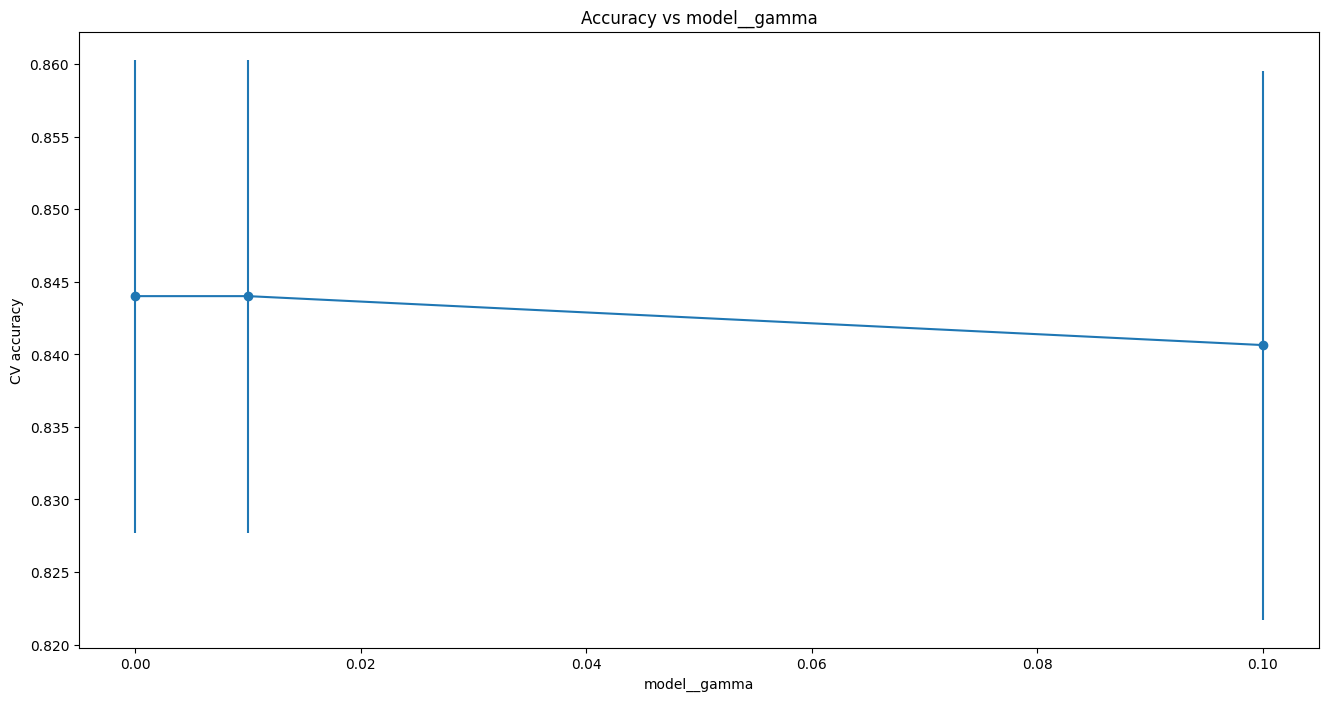

In [291]:
draw_parameter(result, parameter="model__gamma", fixed_params=best_param)

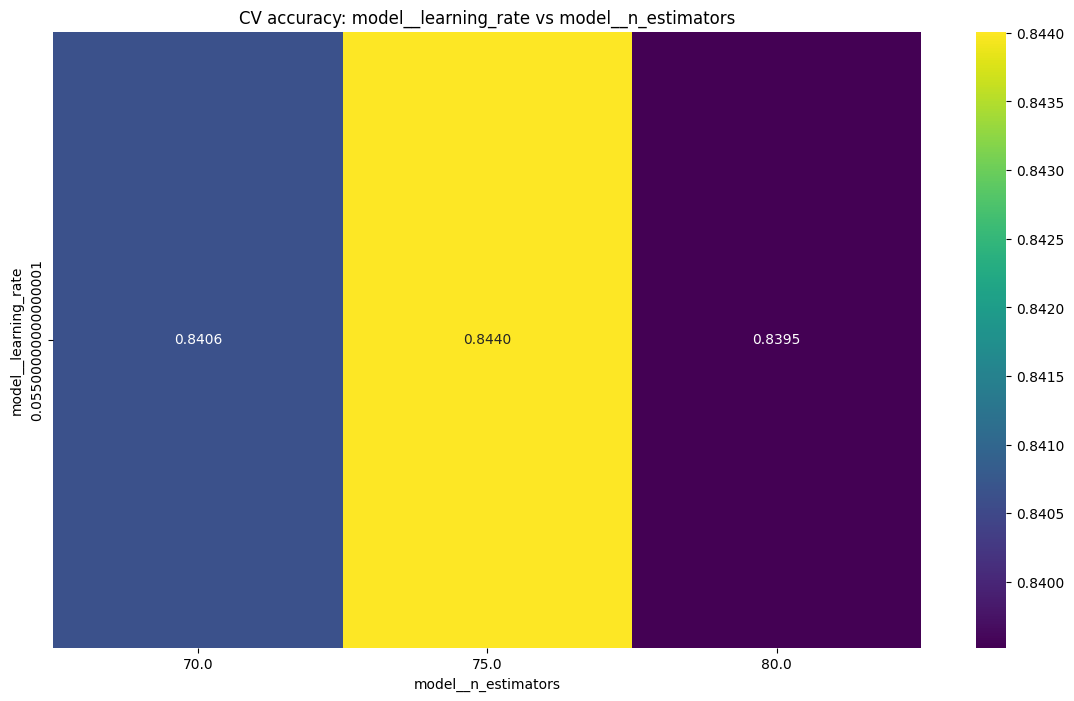

In [292]:
# То есть learning_rate буквально определяет вес каждого нового дерева
draw_heatmap(
    result,
    parameter_x="model__n_estimators",
    parameter_y="model__learning_rate",
    fixed_params=best_param,
)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


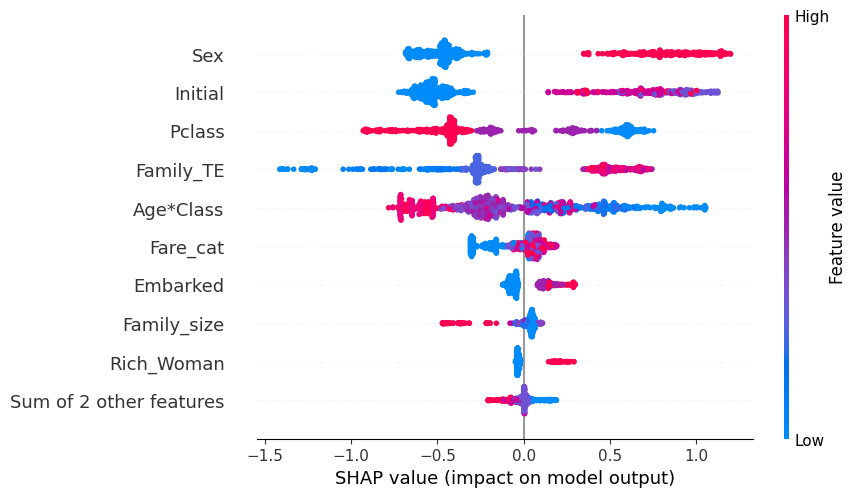

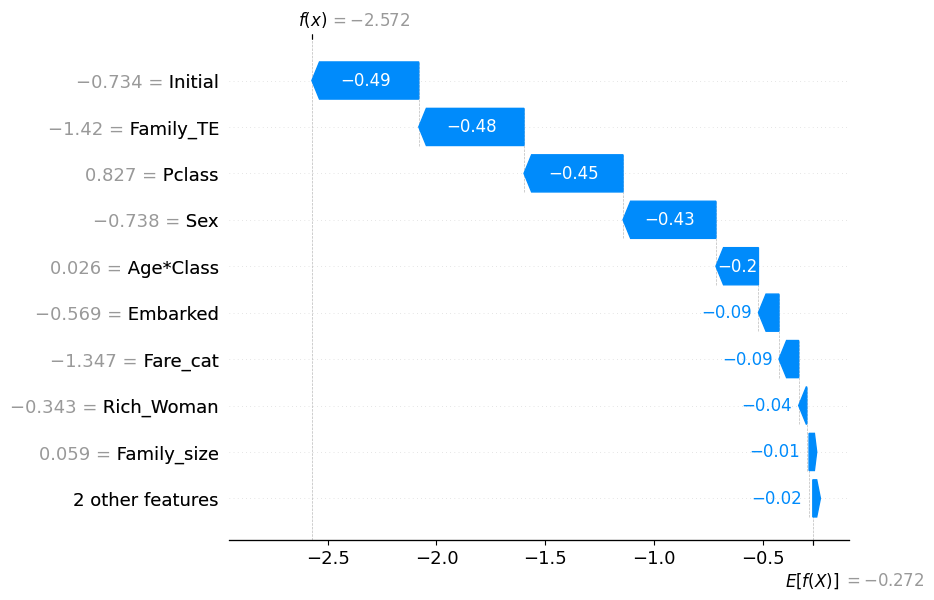

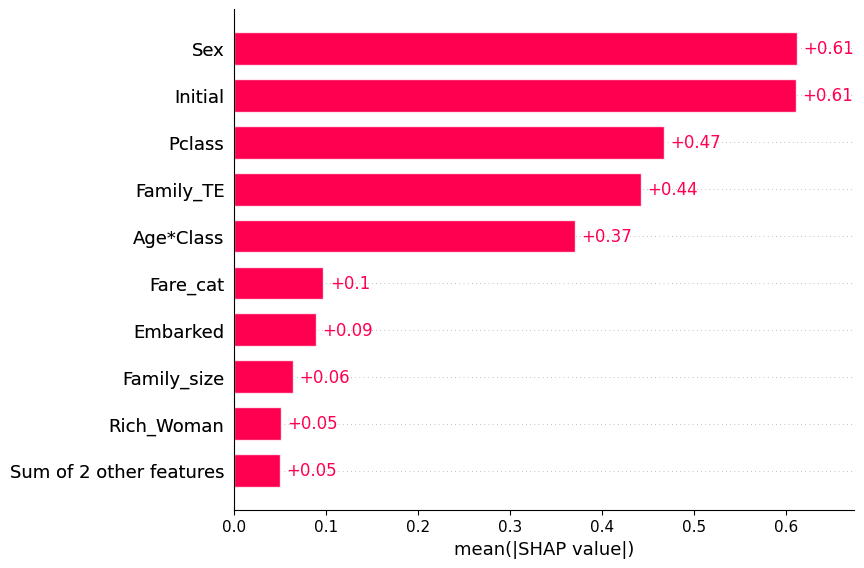

In [293]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_xgboost.named_steps["feature"].transform(X_train)

# 2. Получаем модель
xgboost_model = best_xgboost.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_xgboost[:-1].transform(X_train)

# 4. SHAP
explainer = shap.TreeExplainer(xgboost_model, X_train_transformed)

shap_values_xgboost = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_xgboost, sample_idx=0, feature_names=feature_names)

In [299]:
param_grid_lgbm = {
    "feature__m": [1, 2],
    "model__device": ["cpu"],
    "model__boosting_type": ["gbdt"],
    "model__n_estimators": np.linspace(
        100, 200, 4, dtype=int
    ),  # np.linspace(1, 100, 5, dtype=int)
    "model__learning_rate": np.linspace(
        0.01, 0.1, 5, dtype=float
    ),  # np.linspace(0.01,0.1,5, dtype=float),
    "model__max_depth": [8, 10, 11],  # [4, 5, 6, 8]
    "model__min_child_weight": [1],  # np.linspace(1,5,3,dtype=int),
    "model__n_jobs": [-1],
    "model__subsample": [0.6],  # [0.6, 0.8, 1.0],
    "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0],
    "model__reg_alpha": [0.1, 0.5],  # [0.1, 0.2, 0.4, 0.5,1],
    "model__reg_lambda": [5, 10],  # [0.01,0.1,0.5,5,10],
    "model__objective": ["binary"],
    "model__metric": ["binary_error"],
    "model__min_split_gain": [0.01],  # np.linspace(0.01,0.1,5,dtype=float),
    "model__random_state": [SEED],
}

In [300]:
pipe_LGBM = Pipeline(
    [
        ("feature", FeatureTranformer()),
        ("scaler", StandardScaler()),
        ("model", LGBMClassifier()),
    ]
)

<>:4: SyntaxWarning: invalid escape sequence '\M'
<>:4: SyntaxWarning: invalid escape sequence '\M'
C:\Users\user\AppData\Local\Temp\ipykernel_4664776\3420129854.py:4: SyntaxWarning: invalid escape sequence '\M'
  f'.\Models\lightgmb_best{str(best_scor).replace('.','dot')}.pkl'


GridSearchCV:   0%|          | 0/2400 [00:00<?, ?it/s]

  0%|          | 0/2400 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 342, number of negative: 549
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000166 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 155
[LightGBM] [Info] Number of data points in the train set: 891, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.383838 -> initscore=-0.473288
[LightGBM] [Info] Start training from score -0.473288
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

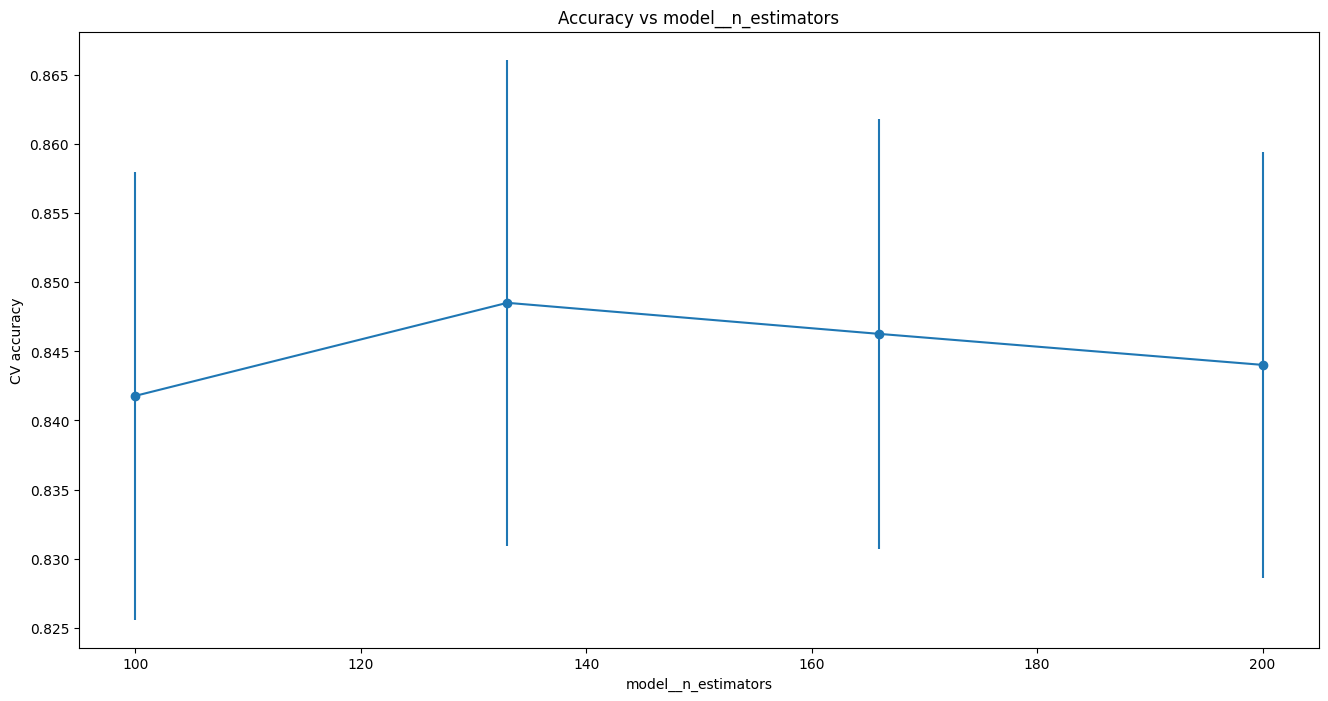

{'feature__m': 2, 'model__boosting_type': 'gbdt', 'model__colsample_bytree': 0.8, 'model__device': 'cpu', 'model__learning_rate': np.float64(0.1), 'model__max_depth': 11, 'model__metric': 'binary_error', 'model__min_child_weight': 1, 'model__min_split_gain': 0.01, 'model__n_estimators': np.int64(133), 'model__n_jobs': -1, 'model__objective': 'binary', 'model__random_state': 42, 'model__reg_alpha': 0.1, 'model__reg_lambda': 10, 'model__subsample': 0.6} 0.8485029188374866


In [301]:
best_lightgmb, best_param, best_scor, result = search_params(
    X_train, y_train, skf, pipe_LGBM, param_grid_lgbm, key_param="model__n_estimators"
)
joblib.dump(
    best_lightgmb, f".\Models\lightgmb_best{str(best_scor).replace('.', 'dot')}.pkl"
)
print(best_param, best_scor)

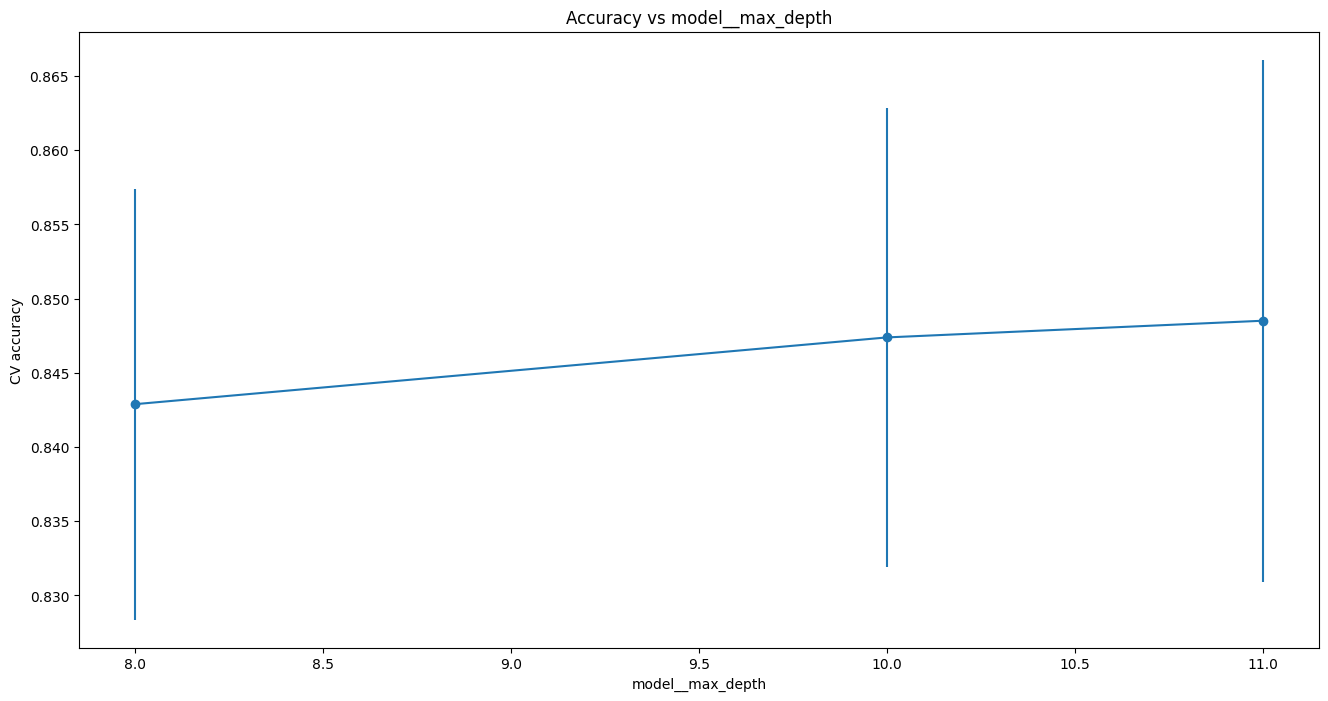

In [302]:
draw_parameter(result, parameter="model__max_depth", fixed_params=best_param)

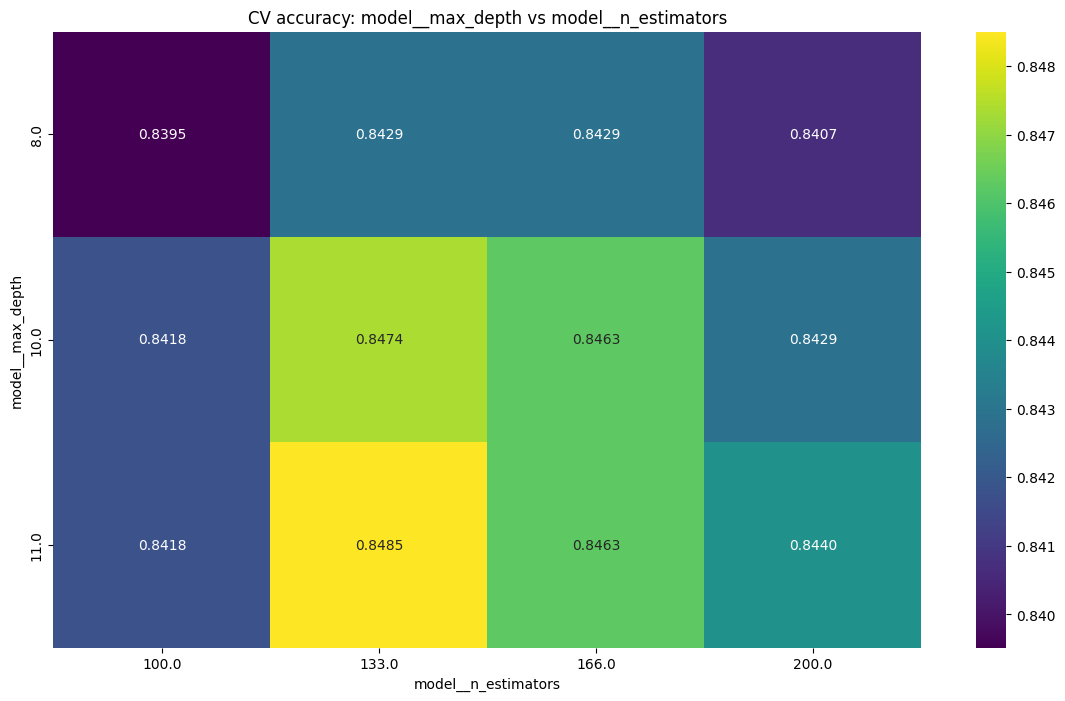

In [304]:
# То есть learning_rate буквально определяет вес каждого нового дерева
draw_heatmap(
    result,
    parameter_x="model__n_estimators",
    parameter_y="model__max_depth",
    fixed_params=best_param,
)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


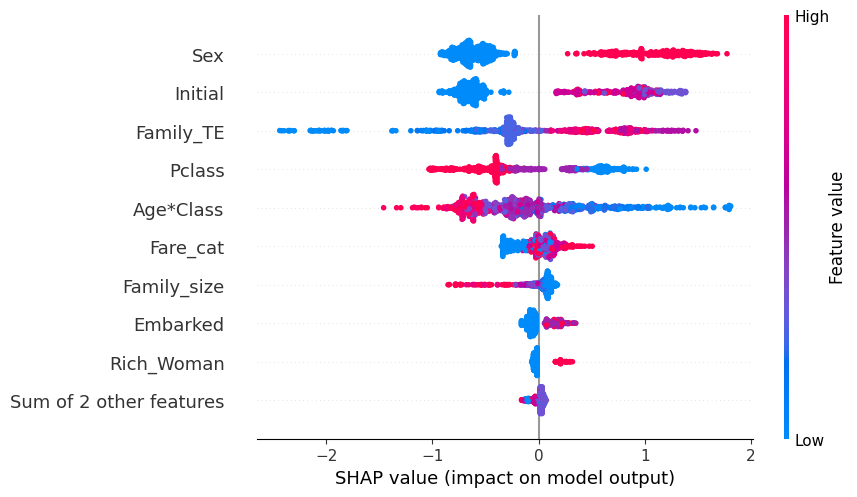

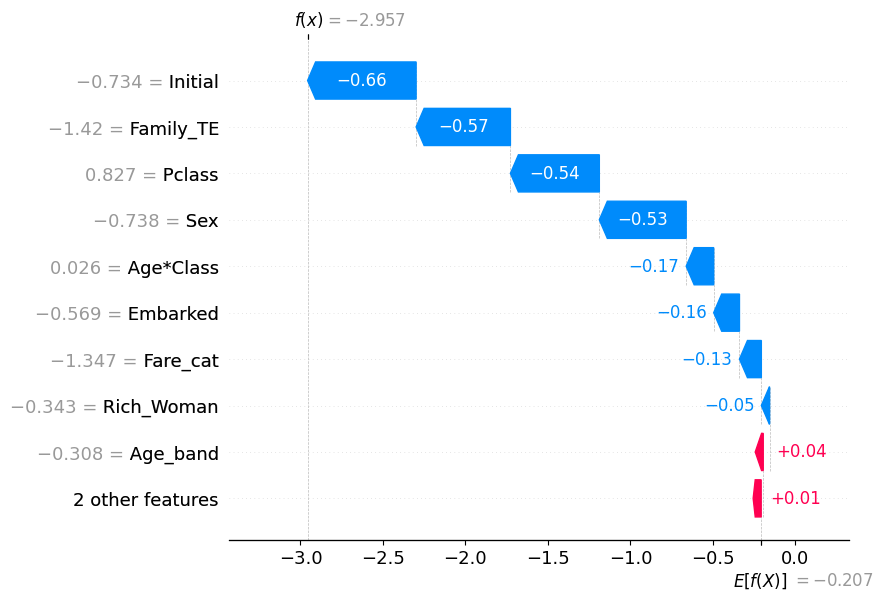

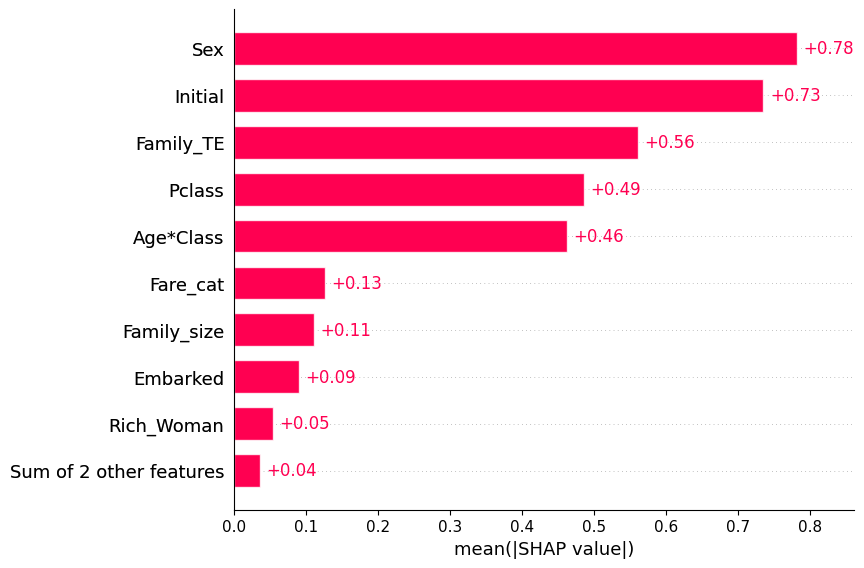

In [305]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_lightgmb.named_steps["feature"].transform(X_train)

# 2. Получаем модель
lightgmb_model = best_lightgmb.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_lightgmb[:-1].transform(X_train)

# 4. SHAP
explainer = shap.TreeExplainer(lightgmb_model, X_train_transformed)

shap_values_lightgmb = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_lightgmb, sample_idx=0, feature_names=feature_names)

In [31]:
param_grid_catboost = {
    "feature__m": [2],  # [0,1,2,4,5],
    "model__boosting_type": ["Plain"],  # ['Plain', 'Ordered'],
    "model__iterations": np.linspace(
        200, 300, 5, dtype=int
    ),  # np.linspace(1, 100, 5, dtype=int)
    "model__learning_rate": [0.05],  # np.linspace(0.01,0.1,5, dtype=float),
    "model__depth": [5],  # [4, 5, 6, 8]
    "model__bootstrap_type": ["Bayesian"],
    "model__thread_count": [-1],
    "model__rsm": [1.0],  # [0.6, 0.8, 1.0],
    "model__l2_leaf_reg": [5, 10],  # [0.01,0.1,0.5,5,10], #[0.01,0.1,0.5,5,10],
    "model__eval_metric": ["Accuracy"],
    "model__border_count": [32],
    "model__loss_function": ["Logloss"],
    "model__random_seed": [SEED],
    "model__bagging_temperature": [0.5, 1],  # [0, 0.5, 1, 2],
    "model__random_strength": [0.5, 1],  # [0, 0.5, 1, 2],
    "model__verbose": [False],
}

In [ ]:
catboost_pipeline = {"catboost": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
        "parameters": {
            "feature__m": [2],  # [0,1,2,4,5],
            "model__boosting_type": ["Plain"],  # ['Plain', 'Ordered'],
            "model__iterations": np.linspace(
                200, 300, 5, dtype=int
            ),  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.05],  # np.linspace(0.01,0.1,5, dtype=float),
            "model__depth": [5],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bayesian"],
            "model__thread_count": [-1],
            "model__rsm": [1.0],  # [0.6, 0.8, 1.0],
            "model__l2_leaf_reg": [5, 10],  # [0.01,0.1,0.5,5,10], #[0.01,0.1,0.5,5,10],
            "model__eval_metric": ["Accuracy"],
            "model__border_count": [32],
            "model__loss_function": ["Logloss"],
            "model__random_seed": [SEED],
            "model__bagging_temperature": [0.5, 1],  # [0, 0.5, 1, 2],
            "model__random_strength": [0.5, 1],  # [0, 0.5, 1, 2],
            "model__verbose": [False],
        },
        'fit_param': {"model__cat_features": FeatureTransformer.cat_cols},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": - 1,
    }
}

<>:31: SyntaxWarning: invalid escape sequence '\M'
<>:31: SyntaxWarning: invalid escape sequence '\M'
C:\Users\user\AppData\Local\Temp\ipykernel_4728932\1860538588.py:31: SyntaxWarning: invalid escape sequence '\M'
  f'.\Models\catboost_best{str(best_scor).replace('.','dot')}.pkl'


GridSearchCV:   0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/200 [00:00<?, ?it/s]

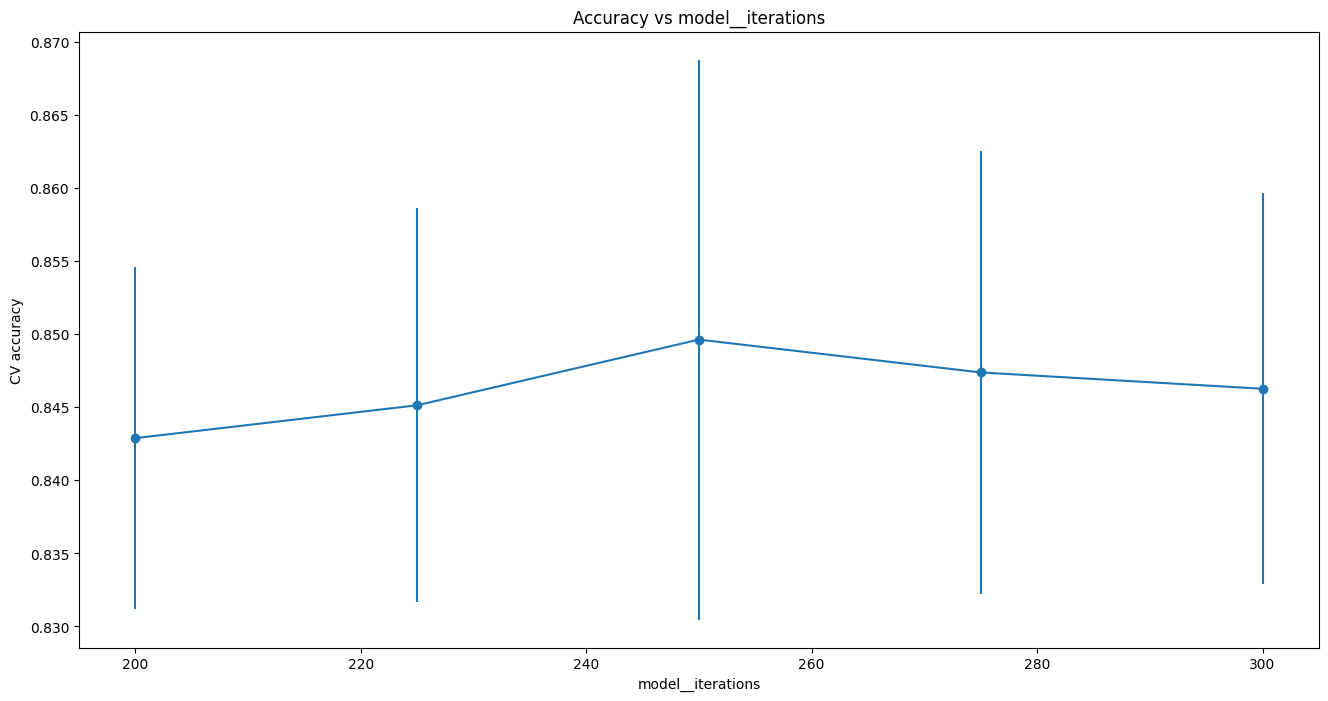

{'feature__m': 2, 'model__bagging_temperature': 1, 'model__boosting_type': 'Plain', 'model__bootstrap_type': 'Bayesian', 'model__border_count': 32, 'model__depth': 5, 'model__eval_metric': 'Accuracy', 'model__iterations': np.int64(250), 'model__l2_leaf_reg': 10, 'model__learning_rate': 0.05, 'model__loss_function': 'Logloss', 'model__random_seed': 42, 'model__random_strength': 1, 'model__rsm': 1.0, 'model__thread_count': -1, 'model__verbose': False} 0.8496202372732409


In [33]:
# param_grid_catboost = [
#     {
#         'boosting_type': ['Plain', 'Ordered'],

#         'iterations': [25, 50, 75, 100],
#         'learning_rate': [0.01, 0.03, 0.05, 0.075, 0.1],
#         'depth': [4, 5, 6, 8],

#         'bootstrap_type': ['Bernoulli'],
#         'subsample': [0.6, 0.8, 1.0],

#         'rsm': [0.6, 0.8, 1.0],

#         'l2_leaf_reg': [0.01, 0.1, 0.5, 5, 10],
#         'random_strength': [0, 0.5, 1, 2],

#         'border_count': [32],

#         'loss_function': ['Logloss'],
#         'eval_metric': ['Accuracy'],

#         'thread_count': [-1],
#         'random_seed': [SEED],
#         'verbose': [False]
#     }
# ]

best_catboost, best_param, best_scor, result = search_params(
    X_train,
    y_train,
    skf,
    pipe_Catboost,
    param_grid_catboost,
    key_param="model__iterations",
)
joblib.dump(
    best_catboost, f".\Models\catboost_best{str(best_scor).replace('.', 'dot')}.pkl"
)
print(best_param, best_scor)

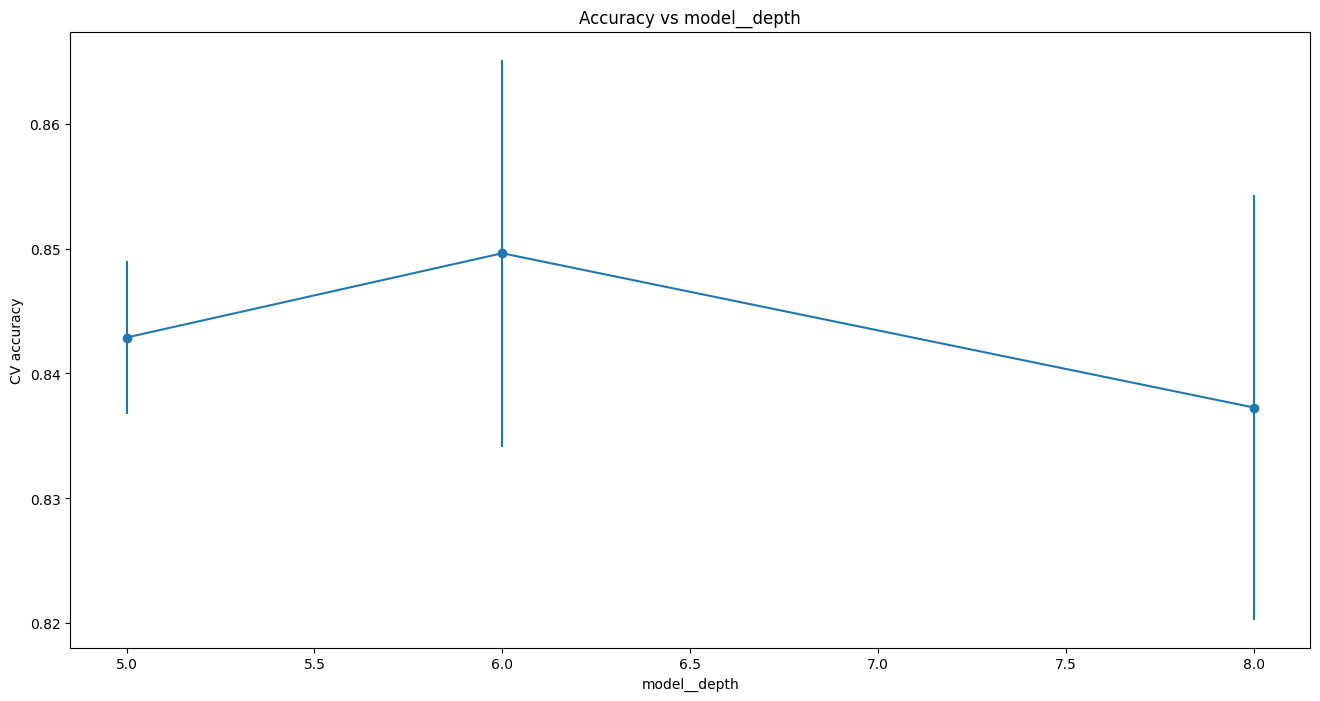

In [21]:
draw_parameter(result, parameter="model__depth", fixed_params=best_param)

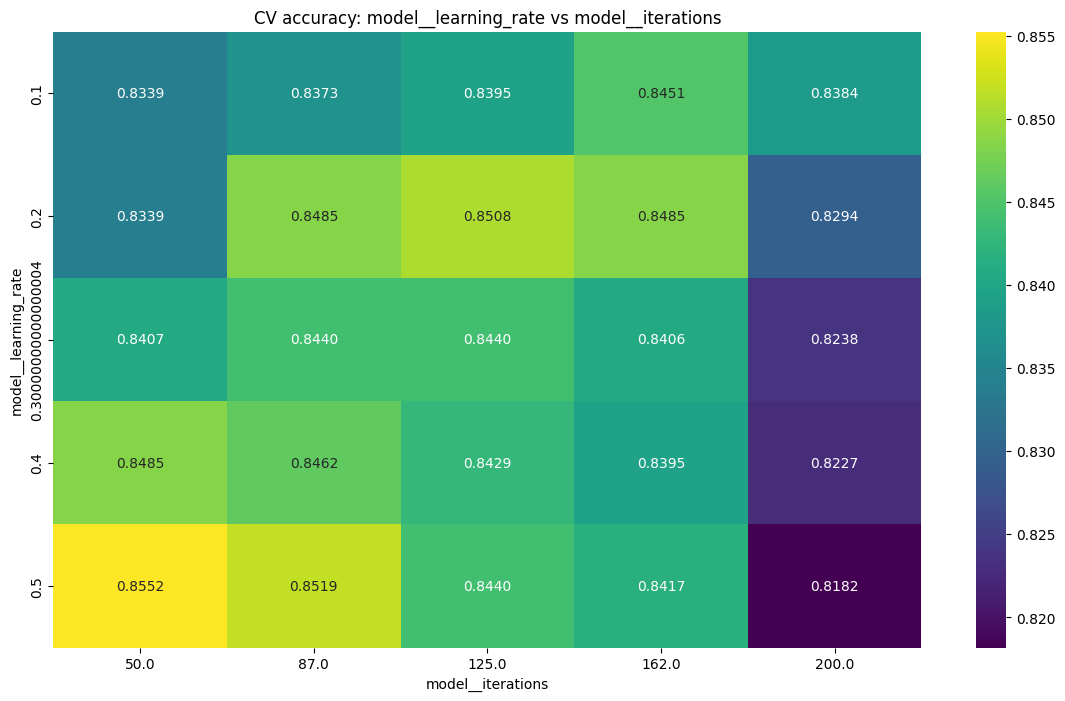

In [310]:
# То есть learning_rate буквально определяет вес каждого нового дерева
draw_heatmap(
    result,
    parameter_x="model__iterations",
    parameter_y="model__learning_rate",
    fixed_params=best_param,
)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


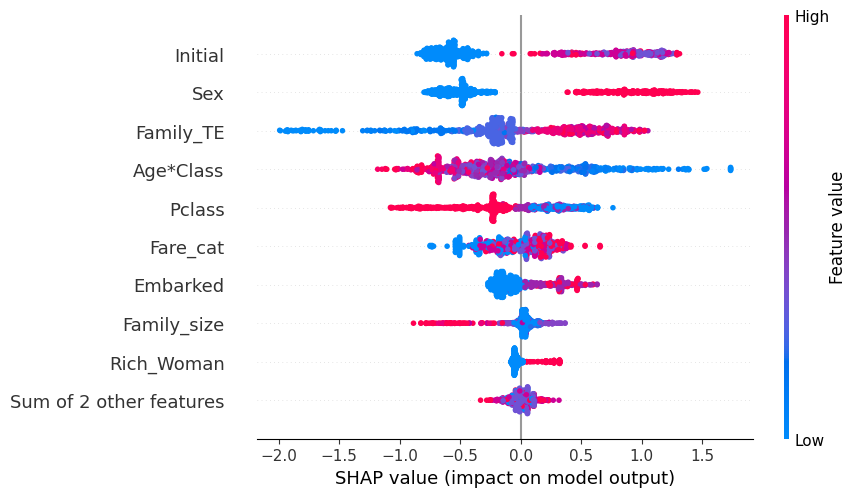

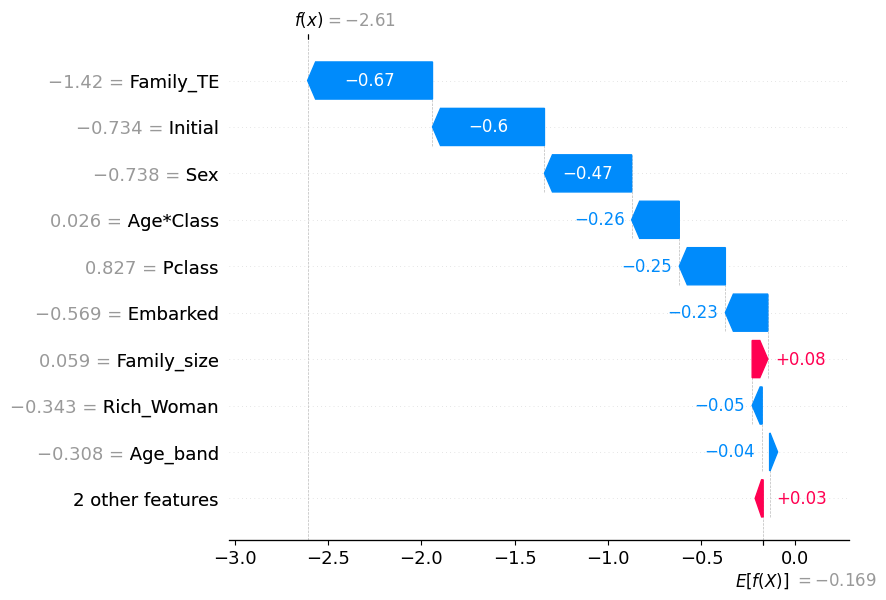

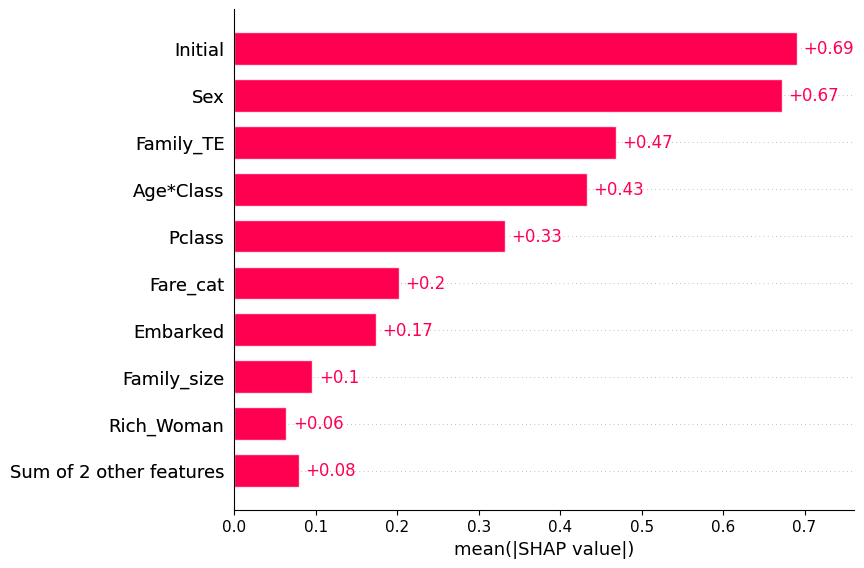

In [311]:
# 1. Получаем данные после FeatureTransformer, но до scaler
X_train_features = best_catboost.named_steps["feature"].transform(X_train)

# 2. Получаем модель
catboost_model = best_catboost.named_steps["model"]

# 3. Получаем данные в том виде, в котором их видит LogisticRegression
X_train_transformed = best_catboost[:-1].transform(X_train)

# 4. SHAP
explainer = shap.TreeExplainer(catboost_model, X_train_transformed)

shap_values_catboost = explainer(X_train_transformed)

# 5. Названия признаков
feature_names = X_train_features.columns.tolist()

# 6. Графики
draw_shap_plots(shap_values_catboost, sample_idx=0, feature_names=feature_names)

In [34]:
import numpy as np
import pandas as pd
import sklearn
import joblib

# ============================================================
# МЕНЯЕШЬ ТОЛЬКО ЭТО
# ============================================================

MODEL_PATH = r"C:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\Titanic\Models\catboost_best0dot8496202372732409.pkl"


# ============================================================
# НЕ МЕНЯЕМ
# ============================================================

TEST_PATH = r"./data/test.csv"
RESULT_PATH = r"./result.csv"


# Те же признаки, что использовались при обучении
X_cols = [
    "FamilyID",
    "Pclass",
    "Sex",
    "Embarked",
    "Initial",
    "Age_band",
    "Rich_Woman",
    "Alone",
    "Family_size",
    "Fare_cat",
    "Age*Class",
]


# ============================================================
# НУЖНО ДЛЯ joblib.load,
# Т.К. ЭТОТ КЛАСС ЕСТЬ В СОХРАНЁННОМ PIPELINE
# ============================================================


class FeatureTranformer(BaseEstimator, TransformerMixin):
    def __init__(self, m: int = 5, y_: float = 0.38):
        self.X_cols = X_cols
        self.m = m
        self.y_ = y_

    def fit(self, X, y):
        # обучаемся только на train fold
        # сохраняем stat
        self.y_ = y.mean()
        X = pd.concat([X, y], axis=1)
        X["Family_TE"] = (
            X["FamilyID"].map(X.groupby("FamilyID")["Survived"].sum())
            + self.m * self.y_
        ) / (X["Family_size"] + 1 + self.m)
        self.stat = X[["FamilyID", "Family_TE"]].drop_duplicates(subset=["FamilyID"])
        self.stat = self.stat.set_index("FamilyID")["Family_TE"]
        return self

    def transform(self, X):
        # используем сохранённые stat
        X_transformed = X.copy()
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(self.stat).fillna(self.y_)
        )
        X_transformed = X_transformed.drop(columns=["FamilyID"])

        return X_transformed

    def fit_transform(self, X, y=None):
        # специальная логика получения train-feature без leakage

        self.fit(X, y)
        X_transformed = pd.concat([X, y], axis=1)
        X_transformed["Family_TE"] = (
            X_transformed["FamilyID"].map(
                X_transformed.groupby("FamilyID")["Survived"].sum()
            )
            - X_transformed["Survived"]
            + self.m * self.y_
        ) / (X_transformed["Family_size"] + self.m)

        X_transformed = X_transformed.drop(columns=["FamilyID", "Survived"])

        return X_transformed


# ============================================================
# ЗАГРУЖАЕМ МОДЕЛЬ
# ============================================================

model = joblib.load(MODEL_PATH)

print("Модель:", type(model))

from sklearn.pipeline import Pipeline

print(type(model))
print(model)

print("\nЭто Pipeline:", isinstance(model, Pipeline))

if isinstance(model, Pipeline):
    print("\nШаги:")
    print(model.named_steps)
# ============================================================
# ЗАГРУЖАЕМ СЫРОЙ KAGGLE TEST
# ============================================================

final_test = pd.read_csv(TEST_PATH)

passenger_id = final_test["PassengerId"].copy()


# ============================================================
# 1. FAMILY ID
# ============================================================
# Ты используешь Ticket как идентификатор группы

final_test["FamilyID"] = (
    final_test["Name"].str.split(",").str[0] + "_" + final_test["Ticket"]
)


# ============================================================
# 2. INITIAL
# ============================================================

final_test["Initial"] = 0
for i in final_test:
    final_test["Initial"] = final_test.Name.str.extract("([A-Za-z]+)\.")

final_test["Initial"].replace(
    [
        "Mlle",
        "Mme",
        "Ms",
        "Dr",
        "Major",
        "Lady",
        "Countess",
        "Jonkheer",
        "Col",
        "Rev",
        "Capt",
        "Sir",
        "Don",
        "Dona",
    ],
    [
        "Miss",
        "Miss",
        "Miss",
        "Mr",
        "Mr",
        "Mrs",
        "Mrs",
        "Other",
        "Other",
        "Other",
        "Mr",
        "Mr",
        "Mr",
        "Mrs",
    ],
    inplace=True,
)


valid_titles = ["Mr", "Mrs", "Miss", "Master", "Other"]

final_test.loc[~final_test["Initial"].isin(valid_titles), "Initial"] = "Other"


# ============================================================
# 3. AGE
# ============================================================

final_test.loc[final_test["Age"].isna() & (final_test["Initial"] == "Mr"), "Age"] = 33


final_test.loc[final_test["Age"].isna() & (final_test["Initial"] == "Mrs"), "Age"] = 36


final_test.loc[
    final_test["Age"].isna() & (final_test["Initial"] == "Master"), "Age"
] = 5


final_test.loc[final_test["Age"].isna() & (final_test["Initial"] == "Miss"), "Age"] = 22


final_test.loc[final_test["Age"].isna() & (final_test["Initial"] == "Other"), "Age"] = (
    46
)


# ============================================================
# 4. AGE BAND
# ============================================================

final_test["Age_band"] = 0


final_test.loc[final_test["Age"] <= 16, "Age_band"] = 0


final_test.loc[(final_test["Age"] > 16) & (final_test["Age"] <= 35), "Age_band"] = 1


final_test.loc[(final_test["Age"] > 35) & (final_test["Age"] <= 48), "Age_band"] = 2


final_test.loc[(final_test["Age"] > 48) & (final_test["Age"] <= 64), "Age_band"] = 3


final_test.loc[final_test["Age"] > 64, "Age_band"] = 4


# ============================================================
# 5. RICH WOMAN
# ============================================================

final_test["Rich_Woman"] = (
    (final_test["Sex"] == "female") & (final_test["Pclass"] == 1)
).astype(int)

# ============================================================
# 6. FAMILY SIZE
# Самого пассажира НЕ учитываем
# ============================================================

final_test["Alone"] = 0
final_test["Family_size"] = final_test["SibSp"] + final_test["Parch"]
final_test.loc[final_test["Family_size"] == 0, "Alone"] = 1


# ============================================================
# 7. ALONE
# ============================================================

final_test["Alone"] = (final_test["Family_size"] == 0).astype(int)


# ============================================================
# 8. FARE CATEGORY
# ============================================================

final_test["Fare_cat"] = 0


final_test.loc[final_test["Fare"] <= 7.91, "Fare_cat"] = 0


final_test.loc[
    (final_test["Fare"] > 7.91) & (final_test["Fare"] <= 14.454), "Fare_cat"
] = 1


final_test.loc[
    (final_test["Fare"] > 14.454) & (final_test["Fare"] <= 31), "Fare_cat"
] = 2


final_test.loc[final_test["Fare"] > 31, "Fare_cat"] = 3


# ============================================================
# 9. AGE * CLASS
# ============================================================

final_test["Age*Class"] = final_test["Age"] * final_test["Pclass"]


# ============================================================
# 10. КОДИРОВАНИЕ КАТЕГОРИЙ
# ============================================================

final_test["Sex"] = final_test["Sex"].replace({"male": 0, "female": 1})


final_test["Embarked"] = final_test["Embarked"].replace({"S": 0, "C": 1, "Q": 2})


final_test["Initial"] = final_test["Initial"].replace(
    {"Mr": 0, "Mrs": 1, "Miss": 2, "Master": 3, "Other": 4}
)


# ============================================================
# 11. ФОРМИРУЕМ X
# ============================================================

X_final = final_test[X_cols].copy()


print("\nПризнаки:")
print(X_final.head())

print("\nРазмер:")
print(X_final.shape)

print("\nПропуски:")
print(X_final.isna().sum())


if X_final.isna().any().any():
    raise ValueError("В данных для модели остались NaN")


# ============================================================
# 12. INFERENCE
#
# Family_TE ВРУЧНУЮ НЕ СОЗДАЁМ.
#
# Pipeline сам вызовет:
#
# FeatureTranformer.transform()
#       ↓
# FamilyID -> Family_TE
#       ↓
# удаление FamilyID
#       ↓
# остальные шаги pipeline
#       ↓
# модель
# ============================================================

prediction = model.predict(X_final)

prediction = np.asarray(prediction).reshape(-1).astype(int)


# ============================================================
# 13. Вероятности — только для проверки
# ============================================================

if hasattr(model, "predict_proba"):
    prediction_proba = model.predict_proba(X_final)[:, 1]

    print("\nСредняя вероятность выживания:", prediction_proba.mean())


# ============================================================
# 14. KAGGLE SUBMISSION
# ============================================================

result = pd.DataFrame({"PassengerId": passenger_id, "Survived": prediction})


# ============================================================
# 15. ПРОВЕРКИ
# ============================================================

assert len(result) == len(final_test)

assert result["Survived"].isna().sum() == 0

assert set(result["Survived"].unique()).issubset({0, 1})


print("\nРаспределение предсказаний:")

print(result["Survived"].value_counts().sort_index())


display(result.head(10))


# ============================================================
# 16. SAVE
# ============================================================

result.to_csv(RESULT_PATH, index=False)

print(f"\nГотово → {RESULT_PATH}")

Модель: <class 'sklearn.pipeline.Pipeline'>
<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('feature',
                 FeatureTranformer(m=2, y_=np.float64(0.3838383838383838))),
                ('scaler', StandardScaler()),
                ('model',
                 CatBoostClassifier(bagging_temperature=1, boosting_type='Plain', bootstrap_type='Bayesian', border_count=32, depth=5, eval_metric='Accuracy', iterations=np.int64(250), l2_leaf_reg=10, learning_rate=0.05, loss_function='Logloss', random_seed=42, random_strength=1, rsm=1.0, verbose=False))])

Это Pipeline: True

Шаги:
{'feature': FeatureTranformer(m=2, y_=np.float64(0.3838383838383838)), 'scaler': StandardScaler(), 'model': CatBoostClassifier(bagging_temperature=1, boosting_type='Plain', bootstrap_type='Bayesian', border_count=32, depth=5, eval_metric='Accuracy', iterations=np.int64(250), l2_leaf_reg=10, learning_rate=0.05, loss_function='Logloss', random_seed=42, random_strength=1, rsm=1.0, verbose=False)}

Признаки:


<>:122: SyntaxWarning: invalid escape sequence '\.'
<>:122: SyntaxWarning: invalid escape sequence '\.'
C:\Users\user\AppData\Local\Temp\ipykernel_4728932\3553658290.py:122: SyntaxWarning: invalid escape sequence '\.'
  final_test['Initial']=final_test.Name.str.extract('([A-Za-z]+)\.')
C:\Users\user\AppData\Local\Temp\ipykernel_4728932\3553658290.py:124: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  final_test['Initial'].replace(['Mlle','Mme','Ms','Dr','Major','Lady','Countess','Jonkheer','Col','Rev','Capt','Sir','Don','Dona']

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0



Готово → ./result.csv


In [320]:
feature_transformer = model.named_steps["feature"]

known_family = X_final["FamilyID"].isin(feature_transformer.stat.index)

print("Совпало FamilyID:", known_family.sum())

print("Всего пассажиров:", len(known_family))

print("Доля известных FamilyID:", known_family.mean())

print("\nПервые совпавшие:")

print(X_final.loc[known_family, "FamilyID"].head(20))

print("\nПервые НЕ совпавшие:")

print(X_final.loc[~known_family, "FamilyID"].head(20))

Совпало FamilyID: 118
Всего пассажиров: 418
Доля известных FamilyID: 0.2822966507177033

Первые совпавшие:
4            Hirvonen_3101298
7             Caldwell_248738
9            Davies_A/4 48871
14        Chaffee_W.E.P. 5734
15    del Carlo_SC/PARIS 2167
20        Rothschild_PC 17603
23          Williams_PC 17597
24           Ryerson_PC 17608
25           Robins_A/5. 3337
26               Ostby_113509
29                Samaan_2662
30           Louch_SC/AH 3085
32             Dean_C.A. 2315
33        Johnston_W./C. 6607
40               Karun_349256
44              Kimball_11753
49          Coutts_C.A. 37671
52              Hocking_29105
53              Fortune_19950
55                Rice_382652
Name: FamilyID, dtype: object

Первые НЕ совпавшие:
0                    Kelly_330911
1                   Wilkes_363272
2                    Myles_240276
3                     Wirz_315154
5                   Svensson_7538
6                 Connolly_330972
8                    Abrahim_2657
10 

### Voting

In [ ]:
# from sklearn.ensemble import VotingClassifier

# catboost_params = best_catboost.get_params()

# catboost_params['iterations'] = int(catboost_params['iterations'])
# catboost_params['learning_rate'] = float(catboost_params['learning_rate'])

# new_ctmodel = CatBoostClassifier(**catboost_params)

# voting = VotingClassifier(
#     estimators=[
#         ('knn', best_knn),
#         ('tree', best_tree),
#         ('ctb', new_ctmodel)
#     ],
#     voting='soft',
#     weights=[2, 1, 3]
# )
# voting.fit(X_train, y_train)

,estimators,"[('knn', ...), ('tree', ...), ...]"
,voting,'soft'
,weights,"[2, 1, ...]"
,n_jobs,None
,flatten_transform,True
,verbose,False
,n_neighbors,np.int64(18)
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,1


### Stacking через log ridge

In [ ]:
# from sklearn.base import clone

# models = [
#     best_knn,
#     best_tree,
#     new_ctmodel
# ]
# meta_models = []
# oof_predictions = np.zeros(
#     (X_train.shape[0], len(models))
# )
# #Модели предсказывают на незнакомой им части данных
# for train_idx, val_idx in skf.split(X_train, y_train):

#     X_tr = X_train[train_idx]
#     X_val = X_train[val_idx]

#     y_tr = y_train[train_idx]

#     for model_idx, model in enumerate(models):

#         m = clone(model)

#         m.fit(X_tr, y_tr)

#         oof_predictions[val_idx, model_idx] = \
#             m.predict_proba(X_val)[:, 1]

In [ ]:
# meta_model = LogisticRegression(C=1.0,random_state=SEED)

# meta_model.fit(
#     oof_predictions,
#     y_train
# )

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
# from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# results = []

# for name, model in main_models.items():

#     pred = model.predict(X_test)
#     proba = model.predict_proba(X_test)[:, 1]

#     results.append({
#         'Model': name,
#         'Accuracy': accuracy_score(y_test, pred),
#         'F1': f1_score(y_test, pred),
#         'ROC-AUC': roc_auc_score(y_test, proba)
#     })

# #Модель усреднения
# pred_proba = (
#     best_knn.predict_proba(X_test)[:, 1] +
#     best_tree.predict_proba(X_test)[:, 1] +
#     best_catboost.predict_proba(X_test)[:, 1]
# ) / 3

# pred = (pred_proba >= 0.5).astype(int)

# results.append({
#         'Model': 'mean_clasifire',
#         'Accuracy': accuracy_score(y_test, pred),
#         'F1': f1_score(y_test, pred),
#         'ROC-AUC': roc_auc_score(y_test, pred_proba)
#     })
# #Meta-model
# meta_models = []

# for model in models:

#     m = clone(model)

#     m.fit(X_train, y_train)

#     meta_models.append(m)

# test_for_meta_model = np.zeros(
#     (X_test.shape[0], len(meta_models))
# )
# for model_idx, model in enumerate(meta_models):
#     test_for_meta_model[:,model_idx] = model.predict_proba(X_test)[:, 1]


# meta_pred = meta_model.predict(test_for_meta_model)
# meta_proba = meta_model.predict_proba(test_for_meta_model)[:, 1]

# results.append({
#         'Model': 'meta_clasifire',
#         'Accuracy': accuracy_score(y_test, meta_pred),
#         'F1': f1_score(y_test, meta_pred),
#         'ROC-AUC': roc_auc_score(y_test, meta_proba)
#     })


# results_df = pd.DataFrame(results)
# results_df

,Model,Accuracy,F1,ROC-AUC
0,logRegression,0.810056,0.760563,0.901480
1,KNN,0.804469,0.751773,0.909202
2,DecisionTree,0.804469,0.755245,0.872909
3,RandomForest,0.821229,0.771429,0.900386
4,CatBoost,0.821229,0.774648,0.899292
5,LightGBM,0.815642,0.765957,0.902188
6,XGBoost,0.821229,0.771429,0.900386
7,VotingClassifier,0.826816,0.783217,0.909717
8,mean_clasifire,0.826816,0.783217,0.908430
9,meta_clasifire,0.826816,0.783217,0.906499
